<a href="https://colab.research.google.com/github/CvChen1127/HRSM/blob/main/HRSM_MAPPING_ML_ParameterTune_Validation_Train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Initial settings (authorize, connect GD, install packages, etc)
初始化设置：授权GEE，连接Google Drive、安装python包

In [1]:
# @title get GEE authorization
import ee

# Trigger the authentication flow.
ee.Authenticate()
# Initialize the library.
ee.Initialize(project='dachuang1-505216')

In [2]:
# @title Connect to my Google Drive
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [3]:
!ls "/content/gdrive/My Drive/"

'Colab Notebooks'   StartFolder


In [3]:
# 整个工作目录复制进Colab
!cp -r '/content/gdrive/My Drive/StartFolder/' '/content/'

In [ ]:
# @title
# Sentinel-2 在各站点、各卫星过境时间的数值
!cp '/content/gdrive/My Drive/NIFA_Download/StartFolder/ML_sites/Sentinel2_arr.npy' /content/
# ERA5-Land 各站点逐小时气象变量
!cp '/content/gdrive/My Drive/NIFA_Download/StartFolder/ML_sites/era5hour_arr.npy' /content/
# Sentinel-1 在各站点、各过境时间的数值
!cp '/content/gdrive/My Drive/NIFA_Download/StartFolder/ML_sites/sentinel1_arr.npy' /content/
# Landsat/HLS 在各站点、各过境时间的数值
!cp '/content/gdrive/My Drive/NIFA_Download/StartFolder/ML_sites/HLSL30_arr.npy' /content/

In [5]:
# @title Install necessary packages 安装Python包
# 在线地图可视化
!pip install folium
# GIS矢量数据
!pip install geopandas
# 多维气象数据
!pip install netCDF4
# GEE ↔ xarray
!pip install --upgrade xee
# GeoTIFF/栅格
!pip install rasterio
# Notebook 交互控件
!pip install ipywidgets
# RMSE、KGE 等评价指标
!pip install permetrics==2.0.0
# 预测区间/不确定性
!pip install mapie
# ML 数据处理、CV 等
!pip install scikit-learn==1.5.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 31.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 37.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [netCDF4]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 22.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.3/573.3 kB 7.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 34.2 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [6]:
# @title Import packages 导入所有包
from mapie.regression import SplitConformalRegressor, ConformalizedQuantileRegressor
import lightgbm as lgb

import folium
from folium import Figure
import geopandas as gpd
import json
import geemap
import numpy as np  # 数组运算
from shapely.geometry import mapping
import pandas as pd
import netCDF4 as nc
import xarray
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.crs import CRS
import math
import time
import os
from datetime import datetime, timedelta
import joblib
import ipywidgets as widgets
from IPython.display import display
from permetrics import RegressionMetric #估计 ML uncertainty 评价指标
import osgeo.gdal as gdal
from osgeo import osr, gdalconst
from scipy.stats import rankdata

## Read sites information and visualize
导入站点数据并可视化

In [12]:
# @title read csv file: points id with coordinates
df_sites = pd.read_csv('/content/StartFolder/ML_sites/ISMN_sites_with_features.csv')
df_sites = df_sites[['ID', 'Longitude', 'Latitude']]
df_sites

,ID,Longitude,Latitude
0,0,-86.55906,34.78534
1,1,-97.08590,37.13130
2,2,-86.89380,35.07470
3,3,-93.73333,42.01667
4,4,-90.65000,33.38333
...,...,...,...
118,118,-88.85130,41.84300
119,119,-96.62220,43.73460
120,120,-84.74650,38.09450
121,121,-83.38960,33.78370


In [13]:
# @title define feature collections
# 把 CSV 里的经纬度转换成 GEE 的 FeatureCollection
lons_sub = ee.List(df_sites['Longitude'].tolist())
lats_sub = ee.List(df_sites['Latitude'].tolist())
idnum_sub = ee.List(df_sites['ID'].tolist())
points = lons_sub.zip(lats_sub).zip(idnum_sub).map(lambda coords: ee.Feature(ee.Geometry.Point(ee.List(coords).get(0)),{'id_num': ee.List(coords).get(1)}))
feature_collection = ee.FeatureCollection(points)

In [14]:
# @title visualization - spatial distribution of sites
# 把这些站点画在地图上，检查位置有没有问题。
import folium
from folium import Figure

fig = Figure(width=800, height=600)
m = folium.Map(location=[42, -95.25], zoom_start=4)


roi_geojson = feature_collection.getInfo()
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google Satellite',
    name='Satellite',
    overlay=True
).add_to(m)
folium.GeoJson(roi_geojson).add_to(m)

fig.add_child(m)

## Read ee.images (constant images)
读取静态特征（LC，DEM，Polaris，）

In [7]:
# @title
import ee

datasets = {
    'ERA5-Land': ee.ImageCollection('ECMWF/ERA5_LAND/HOURLY'),
    'Sentinel-1': ee.ImageCollection('COPERNICUS/S1_GRD'),
    'Sentinel-2': ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED'),
    'HLSL30': ee.ImageCollection('NASA/HLS/HLSL30/v002'),
    'NLCD': ee.ImageCollection('USGS/NLCD_RELEASES/2019_REL/NLCD'),
    'POLARIS sand': ee.ImageCollection(
        'projects/sat-io/open-datasets/polaris/sand_mean'
    )
}

for name, dataset in datasets.items():
    try:
        print(name, 'OK, size =', dataset.size().getInfo())
    except Exception as e:
        print(name, 'ERROR:', e)

ERA5-Land OK, size = 673259
Sentinel-1 OK, size = 3744159
Sentinel-2 OK, size = 36359098
HLSL30 OK, size = 16189767
NLCD OK, size = 8
POLARIS sand OK, size = 6


In [8]:
# @title
import ee

dem_collection = ee.ImageCollection('USGS/3DEP/10m_collection')

print("影像数量：", dem_collection.size().getInfo())

first = dem_collection.first()
print("波段：", first.bandNames().getInfo())

影像数量： 1447
波段： ['elevation']


In [9]:
# @title
import ee

# 1. 读取 USGS 3DEP 10 m
dem_collection = ee.ImageCollection('USGS/3DEP/10m_collection')

# 2. 拼接所有 DEM tile
dem_mosaic = dem_collection.mosaic().select('elevation')

# 3. 给拼接后的 DEM 指定一个统一的 CONUS 投影
# EPSG:5070 = NAD83 / Conus Albers
proj_10m = ee.Projection('EPSG:5070').atScale(10)

dem_10m = (
    dem_mosaic
    .setDefaultProjection(proj_10m)
)

# 4. 从 10 m 聚合到 100 m
dem_100m = (
    dem_10m
    .reduceResolution(
        reducer=ee.Reducer.mean(),
        maxPixels=1024
    )
    .reproject(
        crs='EPSG:5070',
        scale=100
    )
    .rename('elevation')
)

print(
    '统一后的 DEM 投影：',
    dem_10m.projection().getInfo()
)

print(
    '100 m DEM nominal scale：',
    dem_100m.projection().nominalScale().getInfo()
)

统一后的 DEM 投影： {'type': 'Projection', 'crs': 'EPSG:5070', 'transform': [10, 0, 0, 0, 10, 0]}
100 m DEM nominal scale： 100


In [10]:
# @title
# 计算坡度和坡向
terrain = ee.Terrain.products(dem_100m)

slope_100m = terrain.select('slope').rename('slope')
aspect_100m = terrain.select('aspect').rename('aspect')


In [15]:
# @title Export DEM / Slope / Aspect to my GEE Assets

# DEM
task_dem = ee.batch.Export.image.toAsset(
    image=dem_100m,
    description='CONUS_dem100m',
    assetId='projects/dachuang1-505216/assets/CONUS_dem100m',
    region=feature_collection.geometry().bounds(),
    scale=100,
    crs='EPSG:5070',
    maxPixels=1e13
)

# Slope
task_slope = ee.batch.Export.image.toAsset(
    image=slope_100m,
    description='CONUS_dem100m_slopeDegree',
    assetId='projects/dachuang1-505216/assets/CONUS_dem100m_slopeDegree',
    region=feature_collection.geometry().bounds(),
    scale=100,
    crs='EPSG:5070',
    maxPixels=1e13
)

# Aspect
task_aspect = ee.batch.Export.image.toAsset(
    image=aspect_100m,
    description='CONUS_dem100m_aspect',
    assetId='projects/dachuang1-505216/assets/CONUS_dem100m_aspect',
    region=feature_collection.geometry().bounds(),
    scale=100,
    crs='EPSG:5070',
    maxPixels=1e13
)

# 启动三个任务
task_dem.start()
task_slope.start()
task_aspect.start()

print('三个导出任务已提交')

三个导出任务已提交


In [24]:
print('DEM:', task_dem.status()['state'])
print('Slope:', task_slope.status()['state'])
print('Aspect:', task_aspect.status()['state'])

DEM: COMPLETED
Slope: COMPLETED
Aspect: COMPLETED


In [31]:
print("DEM bands:", dem_image.bandNames().getInfo())
print("Slope bands:", slopeDegree_image.bandNames().getInfo())
print("Aspect bands:", aspect_image.bandNames().getInfo())

DEM bands: ['elevation']
Slope bands: ['slope']
Aspect bands: ['aspect']


In [28]:
#@title read images to array（NLCD，POLARTS，DEM）

# Landcover 读取NLCD 土地覆盖
LC = ee.ImageCollection('USGS/NLCD_RELEASES/2019_REL/NLCD').filterDate('2016-01-01', '2022-12-31').select('landcover').first()
lc_proj = LC.projection()

# polaris 读取POLARIS 土壤数据
bd_0_5 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/bd_mean').filterMetadata('system:index', 'equals', 'bd_0_5').first().rename('bd_0_5')
bd_5_15 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/bd_mean').filterMetadata('system:index', 'equals', 'bd_5_15').first().rename('bd_5_15')
bd_15_30 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/bd_mean').filterMetadata('system:index', 'equals', 'bd_15_30').first().rename('bd_15_30')
bd_30_60 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/bd_mean').filterMetadata('system:index', 'equals', 'bd_30_60').first().rename('bd_30_60')
bd_60_100 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/bd_mean').filterMetadata('system:index', 'equals', 'bd_60_100').first().rename('bd_60_100')
bd_0_100 = bd_0_5.multiply(0.05).add(bd_5_15.multiply(0.1)).add(bd_15_30.multiply(0.15)).add(bd_30_60.multiply(0.3)).add(bd_60_100.multiply(0.4)).rename('bd_0_100')
# 0-100 线性平均
clay_0_5 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/clay_mean').filterMetadata('system:index', 'equals', 'clay_0_5').first().rename('clay_0_5')
clay_5_15 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/clay_mean').filterMetadata('system:index', 'equals', 'clay_5_15').first().rename('clay_5_15')
clay_15_30 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/clay_mean').filterMetadata('system:index', 'equals', 'clay_15_30').first().rename('clay_15_30')
clay_30_60 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/clay_mean').filterMetadata('system:index', 'equals', 'clay_30_60').first().rename('clay_30_60')
clay_60_100 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/clay_mean').filterMetadata('system:index', 'equals', 'clay_60_100').first().rename('clay_60_100')
clay_0_100 = clay_0_5.multiply(0.05).add(clay_5_15.multiply(0.1)).add(clay_15_30.multiply(0.15)).add(clay_30_60.multiply(0.3)).add(clay_60_100.multiply(0.4)).rename('clay_0_100')

ksat_0_5 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/ksat_mean').filterMetadata('system:index', 'equals', 'ksat_0_5').first().rename('ksat_0_5')
ksat_5_15 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/ksat_mean').filterMetadata('system:index', 'equals', 'ksat_5_15').first().rename('ksat_5_15')
ksat_15_30 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/ksat_mean').filterMetadata('system:index', 'equals', 'ksat_15_30').first().rename('ksat_15_30')
ksat_30_60 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/ksat_mean').filterMetadata('system:index', 'equals', 'ksat_30_60').first().rename('ksat_30_60')
ksat_60_100 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/ksat_mean').filterMetadata('system:index', 'equals', 'ksat_60_100').first().rename('ksat_60_100')


sand_0_5 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/sand_mean').filterMetadata('system:index', 'equals', 'sand_0_5').first().rename('sand_0_5')
sand_5_15 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/sand_mean').filterMetadata('system:index', 'equals', 'sand_5_15').first().rename('sand_5_15')
sand_15_30 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/sand_mean').filterMetadata('system:index', 'equals', 'sand_15_30').first().rename('sand_15_30')
sand_30_60 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/sand_mean').filterMetadata('system:index', 'equals', 'sand_30_60').first().rename('sand_30_60')
sand_60_100 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/sand_mean').filterMetadata('system:index', 'equals', 'sand_60_100').first().rename('sand_60_100')
sand_0_100 = sand_0_5.multiply(0.05).add(sand_5_15.multiply(0.1)).add(sand_15_30.multiply(0.15)).add(sand_30_60.multiply(0.3)).add(sand_60_100.multiply(0.4)).rename('sand_0_100')

silt_0_5 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/silt_mean').filterMetadata('system:index', 'equals', 'silt_0_5').first().rename('silt_0_5')
silt_5_15 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/silt_mean').filterMetadata('system:index', 'equals', 'silt_5_15').first().rename('silt_5_15')
silt_15_30 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/silt_mean').filterMetadata('system:index', 'equals', 'silt_15_30').first().rename('silt_15_30')
silt_30_60 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/silt_mean').filterMetadata('system:index', 'equals', 'silt_30_60').first().rename('silt_30_60')
silt_60_100 = ee.ImageCollection('projects/sat-io/open-datasets/polaris/silt_mean').filterMetadata('system:index', 'equals', 'silt_60_100').first().rename('silt_60_100')
silt_0_100 = silt_0_5.multiply(0.05).add(silt_5_15.multiply(0.1)).add(silt_15_30.multiply(0.15)).add(silt_30_60.multiply(0.3)).add(silt_60_100.multiply(0.4)).rename('silt_0_100')

polaris = bd_0_5.addBands(bd_0_100)\
          .addBands(ksat_0_5).addBands(ksat_0_5)\
          .addBands(clay_0_5).addBands(clay_0_100)\
          .addBands(sand_0_5).addBands(sand_0_100)\
          .addBands(silt_0_5).addBands(silt_0_100)

polaris_ksat = ksat_0_5.addBands(ksat_5_15).addBands(ksat_15_30).addBands(ksat_30_60).addBands(ksat_60_100)

# DEM 读取DEM 高程数据
dem_image = ee.Image('projects/dachuang1-505216/assets/CONUS_dem100m')
#TWII_image = ee.Image('projects/ee-scai62/assets/CONUS_dem100m_TWII')
aspect_image = ee.Image('projects/dachuang1-505216/assets/CONUS_dem100m_aspect')
slopeDegree_image = ee.Image('projects/dachuang1-505216/assets/CONUS_dem100m_slopeDegree')

dem_image = dem_image.reproject(lc_proj)
#TWII_image = TWII_image.reproject(lc_proj)
aspect_image = aspect_image.reproject(lc_proj)
slopeDegree_image = slopeDegree_image.reproject(lc_proj)
# 统一投影，重采样到100m分辨率
dem_image = dem_image.reproject(crs='EPSG:4326', scale=100)
#TWII_image = TWII_image.reproject(crs='EPSG:4326', scale=100)
aspect_image = aspect_image.reproject(crs='EPSG:4326', scale=100)
slopeDegree_image = slopeDegree_image.reproject(crs='EPSG:4326', scale=100)

In [34]:
# @title extract values from constant images（从栅格中提取站点值）
# DEM，aspect，slopeDegree 三个值从栅格中提出并以数组形式存储
dem_values = dem_image.sampleRegions(collection=feature_collection,scale=100)
elevation_arr = np.array(dem_values.aggregate_array('elevation').getInfo())[:]
dem_idnum_arr = np.array(dem_values.aggregate_array('id_num').getInfo())[:]
#TWII_values = TWII_image.sampleRegions(collection=feature_collection,scale=100)
#TWII_arr = np.array(TWII_values.aggregate_array('b1').getInfo())[:]
aspect_values = aspect_image.sampleRegions(collection=feature_collection,scale=100)
aspect_arr = np.array(aspect_values.aggregate_array('aspect').getInfo())[:]
slopeDegree_values = slopeDegree_image.sampleRegions(collection=feature_collection,scale=100)
slopeDegree_arr = np.array(slopeDegree_values.aggregate_array('slope').getInfo())[:]


# extract pixel values of LC using feature collection
# LC值从栅格中提出并以数组形式存储
LC_values = LC.sampleRegions(collection=feature_collection,scale=100)
landcover_arr = np.array(LC_values.aggregate_array('landcover').getInfo())[:]
LC_idnum_arr = np.array(LC_values.aggregate_array('id_num').getInfo())[:]

# extract pixel values of Polaris soil using feature collection
# Polaris土壤性质值从栅格中提出并以数组形式存储
polaris_values = polaris.sampleRegions(collection=feature_collection,scale=100)
ml_sand_0_5 = np.array(polaris_values.aggregate_array('sand_0_5').getInfo())[:]
ml_sand_0_100 = np.array(polaris_values.aggregate_array('sand_0_100').getInfo())[:]
ml_clay_0_5 = np.array(polaris_values.aggregate_array('clay_0_5').getInfo())[:]
ml_clay_0_100 = np.array(polaris_values.aggregate_array('clay_0_100').getInfo())[:]
ml_bd_0_5 = np.array(polaris_values.aggregate_array('bd_0_5').getInfo())[:]
ml_bd_0_100 = np.array(polaris_values.aggregate_array('bd_0_100').getInfo())[:]
ml_ksat_0_5 = np.array(polaris_values.aggregate_array('ksat_0_5').getInfo())[:]
polaris_idnum_arr = np.array(polaris_values.aggregate_array('id_num').getInfo())[:]


# extract pixel values of Polaris soil using feature collection
polaris_ksat_values = polaris_ksat.sampleRegions(collection=feature_collection,scale=100)
#ksat
ksat_0_5_arr = np.array(polaris_ksat_values.aggregate_array('ksat_0_5').getInfo())[:]
ksat_5_15_arr = np.array(polaris_ksat_values.aggregate_array('ksat_5_15').getInfo())[:]
ksat_15_30_arr = np.array(polaris_ksat_values.aggregate_array('ksat_15_30').getInfo())[:]
ksat_30_60_arr = np.array(polaris_ksat_values.aggregate_array('ksat_30_60').getInfo())[:]
ksat_60_100_arr = np.array(polaris_ksat_values.aggregate_array('ksat_60_100').getInfo())[:]

#最终得到数组：
# elevation_arr
## TWII_arr
# aspect_arr
# slopeDegree_arr
# landcover_arr

# ml_sand_0_5
# ml_sand_0_100

# ml_clay_0_5
# ml_clay_0_100

# ml_bd_0_5
# ml_bd_0_100

# ml_ksat_0_5

# ksat_0_5_arr
# ksat_5_15_arr
# ksat_15_30_arr
# ksat_30_60_arr
# ksat_60_100_arr


In [35]:
print("elevation:", elevation_arr.shape)
print("aspect:", aspect_arr.shape)
print("slope:", slopeDegree_arr.shape)

print("sand 0-5:", ml_sand_0_5.shape)
print("clay 0-5:", ml_clay_0_5.shape)
print("bd 0-5:", ml_bd_0_5.shape)
print("ksat 0-5:", ml_ksat_0_5.shape)
print("ksat 60-100:", ksat_60_100_arr.shape)

elevation: (123,)
aspect: (123,)
slope: (123,)
sand 0-5: (123,)
clay 0-5: (123,)
bd 0-5: (123,)
ksat 0-5: (123,)
ksat 60-100: (123,)


In [36]:
#@title processing constant values（常量值处理）
# DEM异常值处理
elevation_arr[elevation_arr<-1000] = np.nan
# sapect值处理
sinAsp_arr = np.sin(aspect_arr/180*np.pi)
sinAsp_arr[aspect_arr==-1] = 0
cosAsp_arr = np.cos(aspect_arr/180*np.pi)
cosAsp_arr[aspect_arr == -1] = 0
# Ksat值处理
ml_ksat_0_5 = np.power(10, ml_ksat_0_5)  # convert to cm/hr
ksat_0_5_arr = np.power(10, ksat_0_5_arr)
ksat_5_15_arr = np.power(10, ksat_5_15_arr)
ksat_15_30_arr = np.power(10, ksat_15_30_arr)
ksat_30_60_arr = np.power(10, ksat_30_60_arr)
ksat_60_100_arr = np.power(10, ksat_60_100_arr)

d0_5 = 0.05
d5_15 = 0.10
d15_30 = 0.15
d30_60 = 0.30
d60_100 = 0.40
d_total = d0_5 + d5_15 + d15_30 + d30_60 + d60_100
ml_ksat_0_100 = d_total/(d0_5/ksat_0_5_arr +
                                d5_15/ksat_5_15_arr +
                                d15_30/ksat_15_30_arr +
                                d30_60/ksat_30_60_arr +
                                d60_100/ksat_60_100_arr)


In [39]:
# 检查转换后数据有没有问题
print("max ksat at surface: ", ml_ksat_0_5.max())
print("min ksat at surface: ", ml_ksat_0_5.min())
print("max ksat at rootzone: ", ml_ksat_0_100.max())
print("min ksat at rootzone: ", ml_ksat_0_100.min())
print("max slope", slopeDegree_arr.max())
print("min slope", slopeDegree_arr.min())

max ksat at surface:  30.138726934051125
min ksat at surface:  0.12528448473709383
max ksat at rootzone:  24.80740198758528
min ksat at rootzone:  0.060529058583479255
max slope 6
min slope 0


In [40]:
#@title reorganize dataframe （把静态数据整理成一个 DataFrame）

df_constant = pd.DataFrame({
    'ID': dem_idnum_arr,
    'elevation': elevation_arr,
    'sinAspect': sinAsp_arr,
    'cosAspect': cosAsp_arr,
    'slope': slopeDegree_arr,
    'landcover': landcover_arr,
    'sand_0_5[0-100]': ml_sand_0_5,
    'sand_0_100[0-100]': ml_sand_0_100,
    'clay_0_5[0-100]': ml_clay_0_5,
    'clay_0_100[0-100]': ml_clay_0_100,
    'ksat_0_5[cm/hr]': ml_ksat_0_5,
    'ksat_0_100[cm/hr]': ml_ksat_0_100,
    'bd_0_5[g/cm3]': ml_bd_0_5,
    'bd_0_100[g/cm3]': ml_bd_0_100})

merged_df = df_constant.merge(df_sites, on='ID')


refer_id_arr = merged_df['ID'].to_numpy()
refer_lon_arr = merged_df['Longitude'].to_numpy()
refer_lat_arr = merged_df['Latitude'].to_numpy()

refer_id_idx_dict = {}
for i in range(len(refer_id_arr)):
    refer_id_idx_dict[refer_id_arr[i]] = i


len(refer_id_arr)


123

In [44]:
merged_df

,ID,elevation,sinAspect,cosAspect,slope,landcover,sand_0_5[0-100],sand_0_100[0-100],clay_0_5[0-100],clay_0_100[0-100],ksat_0_5[cm/hr],ksat_0_100[cm/hr],bd_0_5[g/cm3],bd_0_100[g/cm3],Longitude,Latitude
0,0,247.417984,0.104528,0.994522,4,81,22.333660,14.076803,23.503902,40.444758,0.930605,1.082764,1.449628,1.369532,-86.55906,34.78534
1,1,362.492523,-0.882948,-0.469472,1,82,33.073750,26.711107,19.272549,29.832326,1.405478,0.738616,1.381225,1.453927,-97.08590,37.13130
2,2,207.857666,0.970296,-0.241922,3,81,25.368773,17.765166,16.532297,30.840107,2.854353,1.472267,1.366998,1.399900,-86.89380,35.07470
3,3,321.358948,0.920505,-0.390731,1,82,27.230228,28.993868,28.155201,28.049255,0.905431,0.764366,1.205557,1.344644,-93.73333,42.01667
4,4,34.918831,-0.139173,0.990268,0,82,17.826572,13.181496,23.957027,36.951194,1.020641,0.600460,1.366186,1.379602,-90.65000,33.38333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118,118,263.736572,0.819152,0.573576,0,82,17.075657,15.849196,26.868950,27.356286,2.282217,2.113966,1.323164,1.368898,-88.85130,41.84300
119,119,484.383301,-0.891007,-0.453990,2,81,8.532757,7.470815,29.936878,30.672246,0.961397,0.872803,1.266587,1.284909,-96.62220,43.73460
120,120,269.290802,-0.898794,-0.438371,1,81,13.054447,10.068678,16.440439,31.202708,3.413749,1.053715,1.284183,1.382641,-84.74650,38.09450
121,121,221.487778,0.325568,-0.945519,2,81,67.308426,38.914001,12.421722,38.215510,3.231924,1.243371,1.501087,1.433158,-83.38960,33.78370


In [42]:
#确认这123个站点的16个静态特征里有没有漏值。
print(merged_df.isna().sum())

ID                   0
elevation            0
sinAspect            0
cosAspect            0
slope                0
landcover            0
sand_0_5[0-100]      0
sand_0_100[0-100]    0
clay_0_5[0-100]      0
clay_0_100[0-100]    0
ksat_0_5[cm/hr]      0
ksat_0_100[cm/hr]    0
bd_0_5[g/cm3]        0
bd_0_100[g/cm3]      0
Longitude            0
Latitude             0
dtype: int64


## Define study area and period
定义研究区和时间范围

In [43]:
# prompt: get the boundary of feature_collection
# 获取所有站点的最小外接矩形
roi = feature_collection.geometry().bounds()
# 时间范围
start_date = '2016-01-01'
end_date = '2025-01-01'

## Read observations
读取目标变量：实测SM

In [ ]:
# 提前处理好了的ISMN表层和根区数据（153个站点，78912个小时）
ISMN_sm_surface_arr = np.load('/content/StartFolder/ML_sites/ISMN_sm_surface_arr.npy')  # 153*78912
ISMN_sm_root_arr = np.load('/content/StartFolder/ML_sites/ISMN_sm_root_arr.npy')  #
ISMN_id_arr = np.load('/content/StartFolder/ML_sites/ISMN_id_arr.npy')
# 提前处理好了的PSA表层和根区数据（312个站点，78912个小时）
PSA_sm_surface_arr = np.load('/content/StartFolder/ML_sites/PSA_sm_surface_arr.npy')  # 312*78912
PSA_sm_root_arr = np.load('/content/StartFolder/ML_sites/PSA_sm_root_arr.npy')
PSA_id_arr = np.load('/content/StartFolder/ML_sites/PSA_id_arr.npy')
# 将两部分站点数据合并，释放内存
referIDArr = np.concatenate([ISMN_id_arr, PSA_id_arr])
obs_sm_surface_arr = np.concatenate([ISMN_sm_surface_arr, PSA_sm_surface_arr], axis=0)
obs_sm_root_arr = np.concatenate([ISMN_sm_root_arr, PSA_sm_root_arr], axis=0)
ISMN_sm_surface_arr = None
ISMN_sm_root_arr = None
PSA_sm_surface_arr = None
PSA_sm_root_arr = None

In [ ]:
# 检查土壤和根区的数据是否同步（站点数，小时数）
print(obs_sm_surface_arr.shape)
print(obs_sm_root_arr.shape)

(465, 78912)
(465, 78912)


In [ ]:
referIDArr - dem_idnum_arr
# 实测 soil moisture 的站点顺序，是否和静态变量的站点顺序完全一致。

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

## Get ee imagecollections
读取动态特征（ERA5-Land
HLSL30
Sentinel-2
Sentinel-1）

In [ ]:
# @title Era5-land（ERA5数据，8个气象特征）

# 时间向前扩容6天
start_date_era5 = (datetime.strptime(start_date, '%Y-%m-%d')- timedelta(hours=120+24)).strftime('%Y-%m-%d')

# era5hour_short存放四个变量（temperature_2m，dewpoint_temperature_2m，wind_10m，surface_pressure）
era5hour_short = ee.ImageCollection("ECMWF/ERA5_LAND/HOURLY")\
                    .filterBounds(roi).filterDate(start_date_era5, end_date)\
                    .map(lambda img: img.addBands(
                        img.select('u_component_of_wind_10m').hypot(img.select('v_component_of_wind_10m')).rename('wind_10m')
                        )).select([
                            'temperature_2m',    # 2m air temperature, K
                            'dewpoint_temperature_2m',  # 2m dew point temperature, K
                            'wind_10m',  # wind speed, m/s
                            'surface_pressure',  # atmospheric surface pressure, Pa
                            ])

# era5hour_mid存放两个变量（SSR：太阳短波辐射 STR：热长波辐射）
era5hour_mid = ee.ImageCollection("ECMWF/ERA5_LAND/HOURLY").filterBounds(roi).filterDate(start_date_era5, end_date).select([
    'surface_solar_radiation_downwards_hourly',  # solar radiation, J
    'surface_thermal_radiation_downwards_hourly',  # thermal radiation, J
    ])

# era5hour_long存放两个变量（AET/evaporation，precipitation）
era5hour_long = ee.ImageCollection("ECMWF/ERA5_LAND/HOURLY").filterBounds(roi).filterDate(start_date_era5, end_date).select([
    'total_evaporation_hourly',  # total evaporation, m
    'total_precipitation_hourly',   # precipitation, m
    ])


In [ ]:
# @title HLSL30（HLSL30气象数据，9个波段）

###note: no scale factor for HLSL30 product.

def bitwiseExtract(img, fromBit, toBit):
  maskSize = ee.Number(1).add(toBit).subtract(fromBit)
  mask = ee.Number(1).leftShift(maskSize).subtract(1)
  return img.rightShift(fromBit).bitwiseAnd(mask)

# remove low quality data
# 去云、云影、雪、水体、差质量气溶胶
def maskHLSL30(image):
  qcDay = image.select('Fmask')
  cloud = bitwiseExtract(qcDay, 1, 1).eq(0)
  cloudshadow = bitwiseExtract(qcDay, 3, 3).eq(0)
  snowice = bitwiseExtract(qcDay, 4, 4).eq(0)
  water = bitwiseExtract(qcDay, 5, 5).eq(0)
  aerosol = bitwiseExtract(qcDay, 6, 7).lte(2)
  mask = cloud.And(cloudshadow).And(snowice).And(water).And(aerosol)

  return    image.updateMask(mask).copyProperties(image, ['system:time_start'])

# 原始影像提取并进行质量控制
HLSL30 = ee.ImageCollection("NASA/HLS/HLSL30/v002").filterBounds(roi)\
    .filterDate(start_date, end_date).map(maskHLSL30) \
		.select(['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B9', 'B10', 'B11'])


In [ ]:
# @title Sentinel-2（Sentinel-2光学遥感数据，10个波段）
# Sentinel-2 images

# old version
# def maskSentinel2(img):
#   cloudOpaqueBitMask = (1 << 10);
#   cloudCirrusMask = (1 << 11);
#   # Get the pixel QA band.
#   qa = img.select('QA60')
#   # Both flags should be set to zero, indicating clear conditions.
#   mask = qa.bitwiseAnd(cloudOpaqueBitMask).eq(0) \
#                 .And(qa.bitwiseAnd(cloudCirrusMask).eq(0))
#   return img.updateMask(mask).copyProperties(img, ['system:time_start'])                  #.multiply(0.0001).toFloat().copyProperties(img, ['mydate'])  # after applying updateMask(). all properties will be lost


def maskSentinel2(img):
  # Get the pixel QA band.
  scl = img.select('SCL')
  mask = scl.neq(8).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
  return img.updateMask(mask).copyProperties(img, ['system:time_start'])

# def add_date(img):
#   date_start = ee.Date(img.get('system:time_start')).format('YYYY-MM-dd-HH')
#   return img.set('mydate', date_start)


Sentinel2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")\
            .filterDate(start_date, end_date).filterBounds(roi)\
            .map(maskSentinel2)\
            .select(['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12'])


In [ ]:
# @title Sentinel-1（Sentinel-1雷达遥感数据，VV极化和VH极化）

# −20<VV<−5，并做平滑处理
def preprocess_vv(image):
    vv_masked = image.updateMask(image.gt(-20).And(image.lt(-5)))
    vv_filtered = vv_masked.convolve(ee.Kernel.gaussian(3))
    return vv_filtered #.rename('VV').copyProperties(image, ['system:time_start'])

# Define preprocessing for VH
# −30<VH<−10，并做平滑处理
def preprocess_vh(image):
    vh_masked = image.updateMask(image.gt(-30).And(image.lt(-10)))
    vh_filtered = vh_masked.convolve(ee.Kernel.gaussian(3))
    return vh_filtered #.rename('VH').copyProperties(image, ['system:time_start'])


def merge_bands(image):
    vv = image.select('VV')
    vh = image.select('VH')
    angle = image.select('angle')

    vv_prep = preprocess_vv(vv)      # Apply mask + smoothing to VV
    vh_prep = preprocess_vh(vh)      # Apply mask + smoothing to VH

    merged = vv_prep.addBands(vh_prep).addBands(angle.rename('angle'))

    return merged.copyProperties(image, ['system:time_start'])

def to_float(image):
    all_bands = image.bandNames()
    return image.select(all_bands).float().copyProperties(image, ['system:time_start'])

Sentinel1 = (
    ee.ImageCollection('COPERNICUS/S1_GRD')
    .filterDate(start_date, end_date)
    .filterBounds(roi)
    .filter(ee.Filter.eq('instrumentMode', 'IW'))
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
    # .filter(ee.Filter.eq('orbitProperties_pass', 'ASCENDING'))
    .sort('SLC_Processing_start')
    .map(merge_bands).map(to_float)
)



## ML models - prepare Xy

In [ ]:
# @title Define weights for ERA5 data（给气象数据设置权重）
def make_weights(n):
    weights = 1.0 / np.arange(n, 0, -1)      # reversed sequence [n ... 1]
    weights = weights / weights.sum()        # normalize
    return weights, ee.List(weights.tolist())

# Short-term (24h)
short_term_weights, ee_short_term_weights = make_weights(24)
# print("Short-term weights:", short_term_weights)

# Mid-term (72h)
mid_term_weights, ee_mid_term_weights = make_weights(72)
# print("Mid-term weights:", mid_term_weights)

# Long-term (120h)
long_term_weights, ee_long_term_weights = make_weights(120)
# print("Long-term weights:", long_term_weights)

# 变量组	                  历史窗口
# Tair / Tdew / wind / pressure	     24 h
# SSR / STR	                 72 h
# evaporation / precipitation	        120 h


In [ ]:
#@title Create year, doy, hour list: doy is an input for ML models, year, doy and hour provide time info for results
start_datetime = datetime(2016, 1, 1, 0, 0, 0)
datetime_list = [start_datetime + timedelta(hours=i) for i in range(78912)]
doy_list = np.array([dt.timetuple().tm_yday for dt in datetime_list])
year_list = np.array([dt.year for dt in datetime_list])
hour_list = np.array([dt.hour for dt in datetime_list])
print(len(doy_list))

78912


In [ ]:
start_datetime = datetime.strptime(start_date, '%Y-%m-%d')
end_datetime = datetime.strptime(end_date, '%Y-%m-%d')  # end_date

num_hours = int((end_datetime - start_datetime).total_seconds()/3600)
print(num_hours)

# 创建 变量×时间×站点，三维数组
era5hour_arr = np.zeros((8, num_hours, len(refer_id_arr)))
sentinel1_arr = np.zeros((3, num_hours, len(refer_id_arr)))
HLSL30_arr = np.zeros((9, num_hours, len(refer_id_arr)))
Sentinel2_arr = np.zeros((10, num_hours, len(refer_id_arr)))

# 初始化
era5hour_arr[:] = np.nan
sentinel1_arr[:] = np.nan
HLSL30_arr[:] = np.nan
Sentinel2_arr[:] = np.nan

78912


In [ ]:
start_datetime = datetime.strptime(start_date, '%Y-%m-%d')
end_datetime = datetime.strptime(end_date, '%Y-%m-%d')  # end_date
current_datetime = start_datetime
tfirsts = []
tlasts = []
deltaa = 10 # hours 切成10h每块进行
while current_datetime < end_datetime:
  tfirsts.append(current_datetime)
  tlasts.append( current_datetime + timedelta(hours=deltaa))
  current_datetime += timedelta(hours=deltaa)

print(len(tfirsts))

7892


In [ ]:
# @title parallel processing  for ERA5-Land（把ERA5提到站点）
import concurrent.futures
def process_day(idx, feature_collection_crop):
  print(f'is running the {idx}th group')
  tfirst = tfirsts[idx]
  tlast = tlasts[idx]

  # ERA5 short
  era5hour_short_sub = era5hour_short.filterDate(tfirst, tlast)

  era5hour_sampled_points = era5hour_short_sub.map(lambda image: image.sampleRegions(
    collection=feature_collection_crop,
    scale=100  # Adjust scale as needed
  )).flatten()
  time.sleep(2) # Adjust the delay as needed
  points_list = era5hour_sampled_points.getInfo()['features']
  system_times = [point['id'] for point in points_list]
  data = [point['properties'] for point in points_list]
  df = pd.DataFrame(data)
  # print(len(df))
  df['id_idx'] = [refer_id_idx_dict[id] for id in df['id_num'].tolist()]
  df['time_idx'] = [int((datetime.strptime(systm[0:8] + systm[9:11], '%Y%m%d%H') - start_datetime).total_seconds()/3600) for systm in system_times]
  grouped_df = df.groupby(['time_idx', 'id_idx']).mean()
  indices = grouped_df.index.tolist()
  for idx in indices:
    era5hour_arr[0, idx[0], idx[1]] = grouped_df.loc[idx, 'temperature_2m']   # 2m air temperature, K
    era5hour_arr[1, idx[0], idx[1]] = grouped_df.loc[idx, 'dewpoint_temperature_2m']   # 2m dew point temperature, K
    era5hour_arr[2, idx[0], idx[1]] = grouped_df.loc[idx, 'wind_10m']   # wind speed, m/s
    era5hour_arr[3, idx[0], idx[1]] = grouped_df.loc[idx, 'surface_pressure']  # atmospheric surface pressure, Pa


  # ERA5 middle
  era5hour_mid_sub = era5hour_mid.filterDate(tfirst, tlast)
  era5hour_sampled_points = era5hour_mid_sub.map(lambda image: image.sampleRegions(
    collection=feature_collection_crop,
    scale=100  # Adjust scale as needed
  )).flatten()
  time.sleep(2) # Adjust the delay as needed
  points_list = era5hour_sampled_points.getInfo()['features']
  system_times = [point['id'] for point in points_list]
  data = [point['properties'] for point in points_list]
  df = pd.DataFrame(data)
  df['id_idx'] = [refer_id_idx_dict[id] for id in df['id_num'].tolist()]
  df['time_idx'] = [int((datetime.strptime(systm[0:8] + systm[9:11], '%Y%m%d%H') - start_datetime).total_seconds()/3600) for systm in system_times]
  grouped_df = df.groupby(['time_idx', 'id_idx']).mean()
  indices = grouped_df.index.tolist()
  for idx in indices:
    era5hour_arr[4, idx[0], idx[1]] = grouped_df.loc[idx, 'surface_solar_radiation_downwards_hourly']   # solar radiation, J
    era5hour_arr[5, idx[0], idx[1]] = grouped_df.loc[idx, 'surface_thermal_radiation_downwards_hourly']   # thermal radiation, J


  # ERA5 long
  era5hour_long_sub = era5hour_long.filterDate(tfirst, tlast)
  era5hour_sampled_points = era5hour_long_sub.map(lambda image: image.sampleRegions(
    collection=feature_collection_crop,
    scale=100  # Adjust scale as needed
  )).flatten()
  time.sleep(2) # Adjust the delay as needed
  points_list = era5hour_sampled_points.getInfo()['features']
  system_times = [point['id'] for point in points_list]
  data = [point['properties'] for point in points_list]
  df = pd.DataFrame(data)
  df['id_idx'] = [refer_id_idx_dict[id] for id in df['id_num'].tolist()]
  df['time_idx'] = [int((datetime.strptime(systm[0:8] + systm[9:11], '%Y%m%d%H') - start_datetime).total_seconds()/3600) for systm in system_times]
  grouped_df = df.groupby(['time_idx', 'id_idx']).mean()
  indices = grouped_df.index.tolist()
  for idx in indices:
    era5hour_arr[6, idx[0], idx[1]] = grouped_df.loc[idx, 'total_evaporation_hourly']   # total evaporation, m
    era5hour_arr[7, idx[0], idx[1]] = grouped_df.loc[idx, 'total_precipitation_hourly']   # precipitation, m


  return idx


if os.path.exists('era5hour_arr.npy'):
  era5hour_arr = np.load('era5hour_arr.npy')
else:
  with concurrent.futures.ThreadPoolExecutor(max_workers=4) as executor:
        results = list(executor.map(lambda idx: process_day(idx, feature_collection), range(len(tfirsts)))) # len(tfirsts)
  print('done')
  np.save('era5hour_arr.npy', era5hour_arr)


time.sleep(10)
# from google.colab import files
# files.download('era5hour_arr.npy')


In [ ]:
print('nan numbers: ',np.count_nonzero(np.isnan(era5hour_arr)))
print('shape of ear5hour_arr: ',era5hour_arr.shape)
nan_indices = np.argwhere(np.isnan(era5hour_arr))
print('third dimension: ', set(nan_indices[:, 2]))

nan numbers:  5050368
shape of ear5hour_arr:  (8, 78912, 465)
third dimension:  {np.int64(400), np.int64(401), np.int64(281), np.int64(410), np.int64(379), np.int64(380), np.int64(381), np.int64(382)}


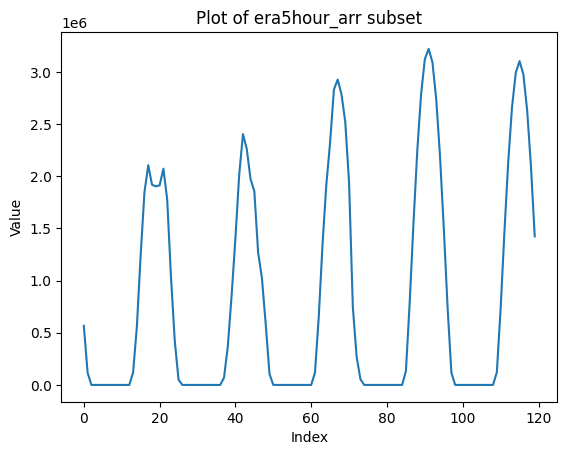

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

y = era5hour_arr[4, 6000:6120, 0]
x = np.arange(len(y))

plt.plot(x, y)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Plot of era5hour_arr subset')
plt.show()

In [ ]:
start_datetime = datetime.strptime(start_date, '%Y-%m-%d')
end_datetime = datetime.strptime(end_date, '%Y-%m-%d')  # end_date
current_datetime = start_datetime
tfirsts = []
tlasts = []
deltaa = 24 # hours
while current_datetime < end_datetime:
  tfirsts.append(current_datetime)
  tlasts.append( current_datetime + timedelta(hours=deltaa))
  current_datetime += timedelta(hours=deltaa)

print(len(tfirsts))

3288


In [ ]:
# @title parallel processing  for HLSL30（同时对三个遥感数据进行站点提取）
import concurrent.futures


def process_day(idx, feature_collection_crop):
  print(f'is running the {idx}th group')
  tfirst = tfirsts[idx]
  tlast = tlasts[idx]

  HLSL30_sub = HLSL30.filterDate(tfirst, tlast)
  Sentinel2_sub = Sentinel2.filterDate(tfirst, tlast)
  sentinel1_sub = Sentinel1.filterDate(tfirst, tlast)

  def sample_with_time(image):
        samples = image.sampleRegions(
            collection=feature_collection_crop,
            scale=100
        )
        return samples.map(lambda f: f.set('system:time_start', image.get('system:time_start')))

  # sentinel2
  Sentinel2_sampled_points = Sentinel2_sub.map(sample_with_time).flatten()
  points_list = Sentinel2_sampled_points.getInfo()['features']
  data = [point['properties'] for point in points_list]
  df = pd.DataFrame(data)
  # print('sentinel2: ',len(df))
  if 'id_num' in df.columns:
    df['datetime'] = pd.to_datetime(df['system:time_start'], unit='ms')
    df['id_idx'] = [refer_id_idx_dict[id] for id in df['id_num'].tolist()]
    df['time_idx'] = ((df['datetime'] - start_datetime).dt.total_seconds() / 3600).astype(int)
    grouped_df = df.groupby(['time_idx', 'id_idx']).mean()
    indices = grouped_df.index.tolist()
    for idx in indices:
      Sentinel2_arr[0, idx[0], idx[1]] = grouped_df.loc[idx, 'B2']
      Sentinel2_arr[1, idx[0], idx[1]] = grouped_df.loc[idx, 'B3']
      Sentinel2_arr[2, idx[0], idx[1]] = grouped_df.loc[idx, 'B4']
      Sentinel2_arr[3, idx[0], idx[1]] = grouped_df.loc[idx, 'B5']
      Sentinel2_arr[4, idx[0], idx[1]] = grouped_df.loc[idx, 'B6']
      Sentinel2_arr[5, idx[0], idx[1]] = grouped_df.loc[idx, 'B7']
      Sentinel2_arr[6, idx[0], idx[1]] = grouped_df.loc[idx, 'B8']
      Sentinel2_arr[7, idx[0], idx[1]] = grouped_df.loc[idx, 'B8A']
      Sentinel2_arr[8, idx[0], idx[1]] = grouped_df.loc[idx, 'B11']
      Sentinel2_arr[9, idx[0], idx[1]] = grouped_df.loc[idx, 'B12']

  # hlsl30
  HLSL30_sampled_points = HLSL30_sub.map(sample_with_time).flatten()
  points_list = HLSL30_sampled_points.getInfo()['features']
  data = [point['properties'] for point in points_list]
  df = pd.DataFrame(data)
  # print('hlsl30: ',len(df))
  if 'id_num' in df.columns:
    df['datetime'] = pd.to_datetime(df['system:time_start'], unit='ms')
    df['id_idx'] = [refer_id_idx_dict[id] for id in df['id_num'].tolist()]
    df['time_idx'] = ((df['datetime'] - start_datetime).dt.total_seconds() / 3600).astype(int)
    grouped_df = df.groupby(['time_idx', 'id_idx']).mean()
    indices = grouped_df.index.tolist()
    for idx in indices:
      HLSL30_arr[0, idx[0], idx[1]] = grouped_df.loc[idx, 'B2']
      HLSL30_arr[1, idx[0], idx[1]] = grouped_df.loc[idx, 'B3']
      HLSL30_arr[2, idx[0], idx[1]] = grouped_df.loc[idx, 'B4']
      HLSL30_arr[3, idx[0], idx[1]] = grouped_df.loc[idx, 'B5']
      HLSL30_arr[4, idx[0], idx[1]] = grouped_df.loc[idx, 'B6']
      HLSL30_arr[5, idx[0], idx[1]] = grouped_df.loc[idx, 'B7']
      HLSL30_arr[6, idx[0], idx[1]] = grouped_df.loc[idx, 'B9']
      HLSL30_arr[7, idx[0], idx[1]] = grouped_df.loc[idx, 'B10']
      HLSL30_arr[8, idx[0], idx[1]] = grouped_df.loc[idx, 'B11']

  # sentinel1
  sentinel1_sampled_points = sentinel1_sub.map(sample_with_time).flatten()
  points_list = sentinel1_sampled_points.getInfo()['features']
  data = [point['properties'] for point in points_list]
  df = pd.DataFrame(data)
  # print('sentinel1: ',len(df))
  if 'id_num' in df.columns:
    df['datetime'] = pd.to_datetime(df['system:time_start'], unit='ms')
    df['id_idx'] = [refer_id_idx_dict[id] for id in df['id_num'].tolist()]
    df['time_idx'] = ((df['datetime'] - start_datetime).dt.total_seconds() / 3600).astype(int)
    grouped_df = df.groupby(['time_idx', 'id_idx']).mean()
    indices = grouped_df.index.tolist()
    for idx in indices:
      sentinel1_arr[0, idx[0], idx[1]] = grouped_df.loc[idx, 'VV']
      sentinel1_arr[1, idx[0], idx[1]] = grouped_df.loc[idx, 'VH']
      sentinel1_arr[2, idx[0], idx[1]] = grouped_df.loc[idx, 'angle']


  return idx



if os.path.exists('Sentinel2_arr.npy'):
  Sentinel2_arr = np.load('Sentinel2_arr.npy')
  HLSL30_arr = np.load('HLSL30_arr.npy')
  sentinel1_arr = np.load('sentinel1_arr.npy')
else:
  with concurrent.futures.ThreadPoolExecutor(max_workers=6) as executor:
        results = list(executor.map(lambda idx: process_day(idx, feature_collection), range(len(tfirsts)))) # len(tfirsts)
  print('done')
  np.save('Sentinel2_arr.npy', Sentinel2_arr)
  np.save('HLSL30_arr.npy', HLSL30_arr)
  np.save('sentinel1_arr.npy', sentinel1_arr)

time.sleep(10)
# from google.colab import files
# files.download('Sentinel2_arr.npy')
# files.download('HLSL30_arr.npy')
# files.download('sentinel1_arr.npy')

In [ ]:
print('shape of HLSL30_arr: ',HLSL30_arr.shape)
print('shape of sentinel1_arr: ',sentinel1_arr.shape)
print('shape of Sentinel2_arr: ',Sentinel2_arr.shape)
print('NON-nan numbers: ',np.count_nonzero(~np.isnan(HLSL30_arr)))
print('NON-nan numbers: ',np.count_nonzero(~np.isnan(sentinel1_arr)))
print('NON-nan numbers: ',np.count_nonzero(~np.isnan(Sentinel2_arr)))


shape of HLSL30_arr:  (9, 78912, 465)
shape of sentinel1_arr:  (3, 78912, 465)
shape of Sentinel2_arr:  (10, 78912, 465)
NON-nan numbers:  615817
NON-nan numbers:  509448
NON-nan numbers:  1508533


In [ ]:
# @title ERA5 processing

#========================short term====================

ear5_d2m_arr_new = era5hour_arr[1, :, :].copy()
print(ear5_d2m_arr_new.shape)
ear5_t2m_arr_new = era5hour_arr[0, :, :].copy()
ear5_wind_arr_new = era5hour_arr[2, :, :].copy()
ear5_sp_arr_new = era5hour_arr[3, :, :].copy()
for row_idx in range(24, ear5_d2m_arr_new.shape[0]):
    ear5_d2m_arr_new[row_idx, :] = np.sum(era5hour_arr[1, row_idx - 23: row_idx + 1, :] * short_term_weights[:, np.newaxis], axis=0)
    ear5_t2m_arr_new[row_idx, :] = np.sum(era5hour_arr[0, row_idx - 23: row_idx + 1, :] * short_term_weights[:, np.newaxis], axis=0)
    ear5_wind_arr_new[row_idx, :] = np.sum(era5hour_arr[2, row_idx - 23: row_idx + 1, :] * short_term_weights[:, np.newaxis], axis=0)
    ear5_sp_arr_new[row_idx, :] = np.sum(era5hour_arr[3, row_idx - 23: row_idx + 1, :] * short_term_weights[:, np.newaxis], axis=0)


# ========================middle term====================

ear5_ssr_arr_new = era5hour_arr[4, :, :].copy()
ear5_str_arr_new = era5hour_arr[5, :, :].copy()
for row_idx in range(72, ear5_str_arr_new.shape[0]):
    ear5_ssr_arr_new[row_idx, :] = np.sum(era5hour_arr[4, row_idx - 71: row_idx + 1, :] * mid_term_weights[:, np.newaxis], axis=0)
    ear5_str_arr_new[row_idx, :] = np.sum(era5hour_arr[5, row_idx - 71: row_idx + 1, :] * mid_term_weights[:, np.newaxis], axis=0)


# ========================long term====================
ear5_e_arr_new = era5hour_arr[6, :, :].copy()
ear5_tp_arr_new = era5hour_arr[7, :, :].copy()
for row_idx in range(120, ear5_e_arr_new.shape[0]):
    ear5_e_arr_new[row_idx, :] = np.sum(era5hour_arr[6, row_idx - 119: row_idx + 1, :] * long_term_weights[:, np.newaxis] , axis=0)
    ear5_tp_arr_new[row_idx, :] = np.sum(era5hour_arr[7, row_idx - 119: row_idx + 1, :] * long_term_weights[:, np.newaxis], axis=0)


(78912, 465)


In [ ]:
print('shape of ear5_d2m_arr_new: ',ear5_d2m_arr_new.shape)
print('shape of ear5_t2m_arr_new: ',ear5_t2m_arr_new.shape)
print('shape of ear5_wind_arr_new: ',ear5_wind_arr_new.shape)
print('shape of ear5_sp_arr_new: ',ear5_sp_arr_new.shape)
print('shape of ear5_ssr_arr_new: ',ear5_ssr_arr_new.shape)
print('shape of ear5_str_arr_new: ',ear5_str_arr_new.shape)
print('shape of ear5_e_arr_new: ',ear5_e_arr_new.shape)
print('shape of ear5_tp_arr_new: ',ear5_tp_arr_new.shape)

shape of ear5_d2m_arr_new:  (78912, 465)
shape of ear5_t2m_arr_new:  (78912, 465)
shape of ear5_wind_arr_new:  (78912, 465)
shape of ear5_sp_arr_new:  (78912, 465)
shape of ear5_ssr_arr_new:  (78912, 465)
shape of ear5_str_arr_new:  (78912, 465)
shape of ear5_e_arr_new:  (78912, 465)
shape of ear5_tp_arr_new:  (78912, 465)


In [ ]:
obs_sm_root_arr.T.shape

(78912, 465)

In [ ]:
#@title Remove inf values of Sentinel 1 - there are some but I do not know why 清除哨兵1数据的异常值
sentinel1_arr[sentinel1_arr>1000] = np.nan

In [ ]:
# @title Prepare Xy for ML and store them in npy file  准备机器学习（ML-1R/1S，2R/2S，3R/3S）的XY
"""-------------------------------------sentinel1-rootzone--------------------------------------"""
# 哨兵一根区 ML-1R训练数据
# X - ID, year, doy, hour, latitude, longitude, dem, slope, sinAspect, cosAspect, TWI,
# bd, sand, clay, ksat, SMAP, d2m, t2m, ssr,str, e, wind, sp, tp,
# VV, VH, angle, CR,  DPSVIm, Pol  - 30
num_ids = len(refer_id_arr)
X = np.zeros((30, num_hours, num_ids))
X[:] = np.nan
X[0] = np.tile(referIDArr, (num_hours, 1))
X[1] = np.repeat(year_list[:, np.newaxis], num_ids, axis=1)
X[2] = np.repeat(doy_list[:, np.newaxis], num_ids, axis=1)
X[3] = np.repeat(hour_list[:, np.newaxis], num_ids, axis=1)
X[4] = np.tile(refer_lat_arr, (num_hours, 1))
X[5] = np.tile(refer_lon_arr, (num_hours, 1))
X[6] = np.tile(elevation_arr, (num_hours, 1))
X[7] = np.tile(slopeDegree_arr, (num_hours, 1))
X[8] = np.tile(sinAsp_arr, (num_hours, 1))
X[9] = np.tile(cosAsp_arr, (num_hours, 1))
X[10] = np.tile(TWII_arr, (num_hours, 1))
X[11] = np.tile(ml_bd_0_100, (num_hours, 1))
X[12] = np.tile(ml_sand_0_100, (num_hours, 1))
X[13] = np.tile(ml_clay_0_100, (num_hours, 1))
X[14] = np.tile(ml_ksat_0_100, (num_hours, 1))
X[15] = 0.3 # smap4_root_arr.T
X[16] = ear5_d2m_arr_new
X[17] = ear5_t2m_arr_new
X[18] = ear5_ssr_arr_new
X[19] = ear5_str_arr_new
X[20] = ear5_e_arr_new
X[21] = ear5_wind_arr_new
X[22] = ear5_sp_arr_new
X[23] = ear5_tp_arr_new
X[24] = sentinel1_arr[0, :, :]
X[25] = sentinel1_arr[1, :, :]
X[26] = sentinel1_arr[2, :, :]
X[27] = sentinel1_arr[0, :, :] / sentinel1_arr[1, :, :]  # CR=VV/VH
X[28] = (sentinel1_arr[0, :, :]**2 + sentinel1_arr[1, :, :]**2)/np.sqrt(2)
X[29] = (sentinel1_arr[0, :, :] + sentinel1_arr[1, :, :]) / (sentinel1_arr[0, :, :] - sentinel1_arr[1, :, :])

X = X.reshape((30, num_hours*num_ids))

y = np.zeros((num_hours, num_ids))
y[:] = obs_sm_root_arr.T
y = y.reshape(1, -1)

X_mask = ~np.any(np.isnan(X), axis=0)
y_mask = ~np.isnan(y[0])

X_all = X[:, X_mask].T
X_valid = X[:, X_mask & y_mask].T
y_valid = y[:, X_mask & y_mask].T

print(X_all.shape)
print(X_valid.shape)
print(y_valid.shape)
print(np.count_nonzero(np.isnan(X_all)))
print(np.count_nonzero(np.isnan(X_valid)))
print(np.count_nonzero(np.isnan(y_valid)))

np.save('sentinel1_rootzone_X_all.npy', X_all)
np.save('sentinel1_rootzone_X_valid.npy', X_valid)
np.save('sentinel1_rootzone_y_valid.npy', y_valid)

"""-------------------------------------sentinel1-surface--------------------------------------"""
# 哨兵一表面 ML-1S训练数据
# X - ID, year, doy, hour, latitude, longitude, dem, slope, sinAspect, cosAspect, TWI,
# bd, sand, clay, ksat, SMAP, d2m, t2m, ssr,str, e, wind, sp, tp,
# VV, VH, angle, CR,  DPSVIm, Pol  - 30
X = np.zeros((30, num_hours, num_ids))
X[:] = np.nan
X[0] = np.tile(referIDArr, (num_hours, 1))
X[1] = np.repeat(year_list[:, np.newaxis], num_ids, axis=1)
X[2] = np.repeat(doy_list[:, np.newaxis], num_ids, axis=1)
X[3] = np.repeat(hour_list[:, np.newaxis], num_ids, axis=1)
X[4] = np.tile(refer_lat_arr, (num_hours, 1))
X[5] = np.tile(refer_lon_arr, (num_hours, 1))
X[6] = np.tile(elevation_arr, (num_hours, 1))
X[7] = np.tile(slopeDegree_arr, (num_hours, 1))
X[8] = np.tile(sinAsp_arr, (num_hours, 1))
X[9] = np.tile(cosAsp_arr, (num_hours, 1))
X[10] = np.tile(TWII_arr, (num_hours, 1))
X[11] = np.tile(ml_bd_0_100, (num_hours, 1))
X[12] = np.tile(ml_sand_0_100, (num_hours, 1))
X[13] = np.tile(ml_clay_0_100, (num_hours, 1))
X[14] = np.tile(ml_ksat_0_100, (num_hours, 1))
X[15] = 0.3 #smap4_surface_arr.T
X[16] = ear5_d2m_arr_new
X[17] = ear5_t2m_arr_new
X[18] = ear5_ssr_arr_new
X[19] = ear5_str_arr_new
X[20] = ear5_e_arr_new
X[21] = ear5_wind_arr_new
X[22] = ear5_sp_arr_new
X[23] = ear5_tp_arr_new
X[24] = sentinel1_arr[0, :, :]
X[25] = sentinel1_arr[1, :, :]
X[26] = sentinel1_arr[2, :, :]
X[27] = sentinel1_arr[0, :, :] / sentinel1_arr[1, :, :]
X[28] = (sentinel1_arr[0, :, :] ** 2 + sentinel1_arr[1, :, :] ** 2) / np.sqrt(2)
X[29] = (sentinel1_arr[0, :, :] + sentinel1_arr[1, :, :]) / (sentinel1_arr[0, :, :] - sentinel1_arr[1, :, :])

X = X.reshape((30, num_hours * num_ids))

y = np.zeros((num_hours, num_ids))
y[:] = obs_sm_surface_arr.T
y = y.reshape(1, -1)

X_mask = ~np.any(np.isnan(X), axis=0)
y_mask = ~np.isnan(y[0])

X_all = X[:, X_mask].T
X_valid = X[:, X_mask & y_mask].T
y_valid = y[:, X_mask & y_mask].T

print(X_all.shape)
print(X_valid.shape)
print(y_valid.shape)
print(np.count_nonzero(np.isnan(X_all)))
print(np.count_nonzero(np.isnan(X_valid)))
print(np.count_nonzero(np.isnan(y_valid)))

np.save('sentinel1_surface_X_all.npy', X_all)
np.save('sentinel1_surface_X_valid.npy', X_valid)
np.save('sentinel1_surface_y_valid.npy', y_valid)

"""-------------------------------------sentinel2-rootzone--------------------------------------"""
# 哨兵二根区 ML-2R训练数据
# X - ID, year, doy, hour, latitude, longitude, dem, slope, sinAspect, cosAspect, TWI,
# bd, sand, clay, ksat, SMAP, d2m, t2m, ssr,str, e, wind, sp, tp, - 24
# B2, B3, B4, B5, B6, B7, B8, B8A, B11, B12, NDVI, NDWI, greenness, brightness, wetness  - 39
X = np.zeros((39, num_hours, num_ids))
X[:] = np.nan
X[0] = np.tile(referIDArr, (num_hours, 1))
X[1] = np.repeat(year_list[:, np.newaxis], num_ids, axis=1)
X[2] = np.repeat(doy_list[:, np.newaxis], num_ids, axis=1)
X[3] = np.repeat(hour_list[:, np.newaxis], num_ids, axis=1)
X[4] = np.tile(refer_lat_arr, (num_hours, 1))
X[5] = np.tile(refer_lon_arr, (num_hours, 1))
X[6] = np.tile(elevation_arr, (num_hours, 1))
X[7] = np.tile(slopeDegree_arr, (num_hours, 1))
X[8] = np.tile(sinAsp_arr, (num_hours, 1))
X[9] = np.tile(cosAsp_arr, (num_hours, 1))
X[10] = np.tile(TWII_arr, (num_hours, 1))
X[11] = np.tile(ml_bd_0_100, (num_hours, 1))
X[12] = np.tile(ml_sand_0_100, (num_hours, 1))
X[13] = np.tile(ml_clay_0_100, (num_hours, 1))
X[14] = np.tile(ml_ksat_0_100, (num_hours, 1))
X[15] = 0.3 #smap4_surface_arr.T
X[16] = ear5_d2m_arr_new
X[17] = ear5_t2m_arr_new
X[18] = ear5_ssr_arr_new
X[19] = ear5_str_arr_new
X[20] = ear5_e_arr_new
X[21] = ear5_wind_arr_new
X[22] = ear5_sp_arr_new
X[23] = ear5_tp_arr_new
X[24] = Sentinel2_arr[0, :, :] * 0.0001 # B2
X[25] = Sentinel2_arr[1, :, :] * 0.0001 # B3
X[26] = Sentinel2_arr[2, :, :] * 0.0001 # B4
X[27] = Sentinel2_arr[3, :, :] * 0.0001 # B5
X[28] = Sentinel2_arr[4, :, :] * 0.0001 # B6
X[29] = Sentinel2_arr[5, :, :] * 0.0001 # B7
X[30] = Sentinel2_arr[6, :, :] * 0.0001 # B8
X[31] = Sentinel2_arr[7, :, :] * 0.0001 # B8A
X[32] = Sentinel2_arr[8, :, :] * 0.0001 # B11
X[33] = Sentinel2_arr[9, :, :] * 0.0001 # B12
X[34] = (X[30] - X[26])/(X[30] + X[26])  # NDVI
X[35] = (X[25] - X[30])/(X[25] + X[30])  # NDWI
X[36] = -0.3599 * X[24] - 0.3533 * X[25] - 0.4734 * X[26] + 0.6633 * X[30] - 0.0087 * X[32] - 0.2856 * X[33] # greenness
X[37] = 0.3510 * X[24] + 0.3813 * X[25] + 0.3437 * X[26] + 0.7196 * X[30] + 0.2396 * X[32] + 0.1949 * X[33]  # brightness
X[38] = 0.2578 * X[24] + 0.2305 * X[25] + 0.0883 * X[26] + 0.1071 * X[30] - 0.7611 * X[32] - 0.5308 * X[33]  # wetness

print('sentinel2-rootzone')
print('mean NDVI: ', np.nanmean(X[34]))
print('mean NDWI: ', np.nanmean(X[35]))
print('mean greenness: ', np.nanmean(X[36]))
print('mean brightness: ', np.nanmean(X[37]))
print('mean wetness: ', np.nanmean(X[38]))

X = X.reshape((39, num_hours * num_ids))

y = np.zeros((num_hours, num_ids))
y[:] = obs_sm_root_arr.T
y = y.reshape(1, -1)

X_mask = ~np.any(np.isnan(X), axis=0)
y_mask = ~np.isnan(y[0])

X_all = X[:, X_mask].T
X_valid = X[:, X_mask & y_mask].T
y_valid = y[:, X_mask & y_mask].T

print(X_all.shape)
print(X_valid.shape)
print(y_valid.shape)
print(np.count_nonzero(np.isnan(X_all)))
print(np.count_nonzero(np.isnan(X_valid)))
print(np.count_nonzero(np.isnan(y_valid)))

np.save('sentinel2_rootzone_X_all.npy', X_all)
np.save('sentinel2_rootzone_X_valid.npy', X_valid)
np.save('sentinel2_rootzone_y_valid.npy', y_valid)

"""-------------------------------------sentinel2-surface--------------------------------------"""
# 哨兵二表面 ML-2S训练数据
# X - ID, year, doy, hour, latitude, longitude, dem, slope, sinAspect, cosAspect, TWI,
# bd, sand, clay, ksat, SMAP, d2m, t2m, ssr,str, e, wind, sp, tp,- 24
#     # B2, B3, B4, B5, B6, B7, B8, B8A, B11, B12, NDVI, NDWI, greenness, brightness, wetness  - 39
X = np.zeros((39, num_hours, num_ids))
X[:] = np.nan
X[0] = np.tile(referIDArr, (num_hours, 1))
X[1] = np.repeat(year_list[:, np.newaxis], num_ids, axis=1)
X[2] = np.repeat(doy_list[:, np.newaxis], num_ids, axis=1)
X[3] = np.repeat(hour_list[:, np.newaxis], num_ids, axis=1)
X[4] = np.tile(refer_lat_arr, (num_hours, 1))
X[5] = np.tile(refer_lon_arr, (num_hours, 1))
X[6] = np.tile(elevation_arr, (num_hours, 1))
X[7] = np.tile(slopeDegree_arr, (num_hours, 1))
X[8] = np.tile(sinAsp_arr, (num_hours, 1))
X[9] = np.tile(cosAsp_arr, (num_hours, 1))
X[10] = np.tile(TWII_arr, (num_hours, 1))
X[11] = np.tile(ml_bd_0_100, (num_hours, 1))
X[12] = np.tile(ml_sand_0_100, (num_hours, 1))
X[13] = np.tile(ml_clay_0_100, (num_hours, 1))
X[14] = np.tile(ml_ksat_0_100, (num_hours, 1))
X[15] = 0.3 #smap4_surface_arr.T
X[16] = ear5_d2m_arr_new
X[17] = ear5_t2m_arr_new
X[18] = ear5_ssr_arr_new
X[19] = ear5_str_arr_new
X[20] = ear5_e_arr_new
X[21] = ear5_wind_arr_new
X[22] = ear5_sp_arr_new
X[23] = ear5_tp_arr_new
X[24] = Sentinel2_arr[0, :, :] * 0.0001 # B2
X[25] = Sentinel2_arr[1, :, :] * 0.0001 # B3
X[26] = Sentinel2_arr[2, :, :] * 0.0001 # B4
X[27] = Sentinel2_arr[3, :, :] * 0.0001 # B5
X[28] = Sentinel2_arr[4, :, :] * 0.0001 # B6
X[29] = Sentinel2_arr[5, :, :] * 0.0001 # B7
X[30] = Sentinel2_arr[6, :, :] * 0.0001 # B8
X[31] = Sentinel2_arr[7, :, :] * 0.0001 # B8A
X[32] = Sentinel2_arr[8, :, :] * 0.0001 # B11
X[33] = Sentinel2_arr[9, :, :] * 0.0001 # B12
X[34] = (X[30] - X[26])/(X[30] + X[26])  # NDVI
X[35] = (X[25] - X[30])/(X[25] + X[30])  # NDWI
X[36] = -0.3599 * X[24] - 0.3533 * X[25] - 0.4734 * X[26] + 0.6633 * X[30] - 0.0087 * X[32] - 0.2856 * X[33] # greenness
X[37] = 0.3510 * X[24] + 0.3813 * X[25] + 0.3437 * X[26] + 0.7196 * X[30] + 0.2396 * X[32] + 0.1949 * X[33]  # brightness
X[38] = 0.2578 * X[24] + 0.2305 * X[25] + 0.0883 * X[26] + 0.1071 * X[30] - 0.7611 * X[32] - 0.5308 * X[33]  # wetness

print('sentinel2-surface')
print('mean NDVI: ', np.nanmean(X[34]))
print('mean NDWI: ', np.nanmean(X[35]))
print('mean greenness: ', np.nanmean(X[36]))
print('mean brightness: ', np.nanmean(X[37]))
print('mean wetness: ', np.nanmean(X[38]))

X = X.reshape((39, num_hours * num_ids))

y = np.zeros((num_hours, num_ids))
y[:] = obs_sm_surface_arr.T
y = y.reshape(1, -1)

X_mask = ~np.any(np.isnan(X), axis=0)
y_mask = ~np.isnan(y[0])

X_all = X[:, X_mask].T
X_valid = X[:, X_mask & y_mask].T
y_valid = y[:, X_mask & y_mask].T

print(X_all.shape)
print(X_valid.shape)
print(y_valid.shape)
print(np.count_nonzero(np.isnan(X_all)))
print(np.count_nonzero(np.isnan(X_valid)))
print(np.count_nonzero(np.isnan(y_valid)))

np.save('sentinel2_surface_X_all.npy', X_all)
np.save('sentinel2_surface_X_valid.npy', X_valid)
np.save('sentinel2_surface_y_valid.npy', y_valid)

"""-------------------------------------HLSL30-rootzone--------------------------------------"""
# HLSL30-根区 ML-3R训练数据
# X - ID, year, doy, hour, latitude, longitude, dem, slope, sinAspect, cosAspect, TWI,
# bd, sand, clay, ksat, SMAP, d2m, t2m, ssr,str, e, wind, sp, tp, - 24
# B2, B3, B4, B5, B6, B7, B10, B11, SZA, SAA, VZA, VAA, NDVI, NDWI, greenness, brightness, wetness  - 41
X = np.zeros((41, num_hours, num_ids))
X[:] = np.nan
X[0] = np.tile(referIDArr, (num_hours, 1))
X[1] = np.repeat(year_list[:, np.newaxis], num_ids, axis=1)
X[2] = np.repeat(doy_list[:, np.newaxis], num_ids, axis=1)
X[3] = np.repeat(hour_list[:, np.newaxis], num_ids, axis=1)
X[4] = np.tile(refer_lat_arr, (num_hours, 1))
X[5] = np.tile(refer_lon_arr, (num_hours, 1))
X[6] = np.tile(elevation_arr, (num_hours, 1))
X[7] = np.tile(slopeDegree_arr, (num_hours, 1))
X[8] = np.tile(sinAsp_arr, (num_hours, 1))
X[9] = np.tile(cosAsp_arr, (num_hours, 1))
X[10] = np.tile(TWII_arr, (num_hours, 1))
X[11] = np.tile(ml_bd_0_100, (num_hours, 1))
X[12] = np.tile(ml_sand_0_100, (num_hours, 1))
X[13] = np.tile(ml_clay_0_100, (num_hours, 1))
X[14] = np.tile(ml_ksat_0_100, (num_hours, 1))
X[15] = 0.3 #smap4_surface_arr.T
X[16] = ear5_d2m_arr_new
X[17] = ear5_t2m_arr_new
X[18] = ear5_ssr_arr_new
X[19] = ear5_str_arr_new
X[20] = ear5_e_arr_new
X[21] = ear5_wind_arr_new
X[22] = ear5_sp_arr_new
X[23] = ear5_tp_arr_new
X[24] = HLSL30_arr[0, :, :]  # B2
X[25] = HLSL30_arr[1, :, :]   # B3
X[26] = HLSL30_arr[2, :, :]   # B4
X[27] = HLSL30_arr[3, :, :]   # B5
X[28] = HLSL30_arr[4, :, :]  # B6
X[29] = HLSL30_arr[5, :, :]   # B7
X[30] = HLSL30_arr[7, :, :]   # B10
X[31] = HLSL30_arr[8, :, :]   # B11
X[32] = 90 #HLSL30_arr[9, :, :]   # SZA
X[33] = 90 #HLSL30_arr[10, :, :]  # SAA
X[34] = 90 #HLSL30_arr[11, :, :]  # VZA
X[35] = 90 #HLSL30_arr[12, :, :]  # VAA
X[36] = (X[27] - X[26]) / (X[27] + X[26])  # NDVI
X[37] = (X[25] - X[27]) / (X[25] + X[27])  # NDWI
X[38] = -0.2941 * X[24] - 0.243 * X[25] - 0.5424 * X[26] +0.7276 * X[27] +0.0713 * X[28] - 0.1608 * X[29]  # greenness
X[39] = 0.3510 * X[24] + 0.3813 * X[25] + 0.3437 * X[26] + 0.7196 * X[27] + 0.2396 * X[28] + 0.1949 * X[29]  # brightness
X[40] = 0.2578 * X[24] + 0.2305 * X[25] + 0.0883 * X[26] + 0.1071 * X[27] - 0.7611 * X[28] - 0.5308 * X[29]  # wetness

print('HLSL30-rootzone')
print('mean NDVI: ', np.nanmean(X[36]))
print('mean NDWI: ', np.nanmean(X[37]))
print('mean greenness: ', np.nanmean(X[38]))
print('mean brightness: ', np.nanmean(X[39]))
print('mean wetness: ', np.nanmean(X[40]))

X = X.reshape((41, num_hours * num_ids))

y = np.zeros((num_hours, num_ids))
y[:] = obs_sm_root_arr.T
y = y.reshape(1, -1)

X_mask = ~np.any(np.isnan(X), axis=0)
y_mask = ~np.isnan(y[0])

X_all = X[:, X_mask].T
X_valid = X[:, X_mask & y_mask].T
y_valid = y[:, X_mask & y_mask].T

print(X_all.shape)
print(X_valid.shape)
print(y_valid.shape)
print(np.count_nonzero(np.isnan(X_all)))
print(np.count_nonzero(np.isnan(X_valid)))
print(np.count_nonzero(np.isnan(y_valid)))

np.save('HLSL30_rootzone_X_all.npy', X_all)
np.save('HLSL30_rootzone_X_valid.npy', X_valid)
np.save('HLSL30_rootzone_y_valid.npy', y_valid)

"""-------------------------------------HLSL30-surface--------------------------------------"""
# HLSL30表面 ML-3S训练数据
# X - ID, year, doy, hour, latitude, longitude, dem, slope, sinAspect, cosAspect, TWI,
# bd, sand, clay, ksat, SMAP, d2m, t2m, ssr,str, e, wind, sp, tp,- 24
#    B2, B3, B4, B5, B6, B7, B10, B11, SZA, SAA, VZA, VAA, NDVI, NDWI, greenness, brightness, wetness  - 41
X = np.zeros((41, num_hours, num_ids))
X[:] = np.nan
X[0] = np.tile(referIDArr, (num_hours, 1))
X[1] = np.repeat(year_list[:, np.newaxis], num_ids, axis=1)
X[2] = np.repeat(doy_list[:, np.newaxis], num_ids, axis=1)
X[3] = np.repeat(hour_list[:, np.newaxis], num_ids, axis=1)
X[4] = np.tile(refer_lat_arr, (num_hours, 1))
X[5] = np.tile(refer_lon_arr, (num_hours, 1))
X[6] = np.tile(elevation_arr, (num_hours, 1))
X[7] = np.tile(slopeDegree_arr, (num_hours, 1))
X[8] = np.tile(sinAsp_arr, (num_hours, 1))
X[9] = np.tile(cosAsp_arr, (num_hours, 1))
X[10] = np.tile(TWII_arr, (num_hours, 1))
X[11] = np.tile(ml_bd_0_100, (num_hours, 1))
X[12] = np.tile(ml_sand_0_100, (num_hours, 1))
X[13] = np.tile(ml_clay_0_100, (num_hours, 1))
X[14] = np.tile(ml_ksat_0_100, (num_hours, 1))
X[15] = 0.3 #smap4_surface_arr.T
X[16] = ear5_d2m_arr_new
X[17] = ear5_t2m_arr_new
X[18] = ear5_ssr_arr_new
X[19] = ear5_str_arr_new
X[20] = ear5_e_arr_new
X[21] = ear5_wind_arr_new
X[22] = ear5_sp_arr_new
X[23] = ear5_tp_arr_new
X[24] = HLSL30_arr[0, :, :]  # B2
X[25] = HLSL30_arr[1, :, :]  # B3
X[26] = HLSL30_arr[2, :, :]  # B4
X[27] = HLSL30_arr[3, :, :]  # B5
X[28] = HLSL30_arr[4, :, :]  # B6
X[29] = HLSL30_arr[5, :, :]  # B7
X[30] = HLSL30_arr[7, :, :] # B10
X[31] = HLSL30_arr[8, :, :]  # B11
X[32] = 90 #HLSL30_arr[9, :, :]  # SZA
X[33] = 90 #HLSL30_arr[10, :, :]  # SAA
X[34] = 90 #HLSL30_arr[11, :, :]  # VZA
X[35] = 90 #HLSL30_arr[12, :, :]  # VAA
X[36] = (X[27] - X[26]) / (X[27] + X[26])  # NDVI
X[37] = (X[25] - X[27]) / (X[25] + X[27])  # NDWI
X[38] = -0.2941 * X[24] - 0.243 * X[25] - 0.5424 * X[26] +0.7276 * X[27] +0.0713 * X[28] - 0.1608 * X[29]  # greenness
X[39] = 0.3510 * X[24] + 0.3813 * X[25] + 0.3437 * X[26] + 0.7196 * X[27] + 0.2396 * X[28] + 0.1949 * X[29]  # brightness
X[40] = 0.2578 * X[24] + 0.2305 * X[25] + 0.0883 * X[26] + 0.1071 * X[27] - 0.7611 * X[28] - 0.5308 * X[29]  # wetness

print('HLSL30-surface')
print('mean NDVI: ', np.nanmean(X[36]))
print('mean NDWI: ', np.nanmean(X[37]))
print('mean greenness: ', np.nanmean(X[38]))
print('mean brightness: ', np.nanmean(X[39]))
print('mean wetness: ', np.nanmean(X[40]))

X = X.reshape((41, num_hours * num_ids))

y = np.zeros((num_hours, num_ids))
y[:] = obs_sm_surface_arr.T
y = y.reshape(1, -1)

X_mask = ~np.any(np.isnan(X), axis=0)
y_mask = ~np.isnan(y[0])

X_all = X[:, X_mask].T
X_valid = X[:, X_mask & y_mask].T
y_valid = y[:, X_mask & y_mask].T

print(X_all.shape)
print(X_valid.shape)
print(y_valid.shape)
print(np.count_nonzero(np.isnan(X_all)))
print(np.count_nonzero(np.isnan(X_valid)))
print(np.count_nonzero(np.isnan(y_valid)))

np.save('HLSL30_surface_X_all.npy', X_all)
np.save('HLSL30_surface_X_valid.npy', X_valid)
np.save('HLSL30_surface_y_valid.npy', y_valid)


print()

(165922, 30)
(24538, 30)
(24538, 1)
0
0
0
(165922, 30)
(37599, 30)
(37599, 1)
0
0
0
sentinel2-rootzone
mean NDVI:  0.4808724383791793
mean NDWI:  -0.5118954785707435
mean greenness:  0.03654766765533724
mean brightness:  0.41780215115326946
mean wetness:  -0.229207170217558
(148287, 39)
(25618, 39)
(25618, 1)
0
0
0
sentinel2-surface
mean NDVI:  0.4808724383791793
mean NDWI:  -0.5118954785707435
mean greenness:  0.03654766765533724
mean brightness:  0.41780215115326946
mean wetness:  -0.229207170217558
(148287, 39)
(36867, 39)
(36867, 1)
0
0
0
HLSL30-rootzone
mean NDVI:  0.5183910973628286
mean NDWI:  -0.5567367822884184
mean greenness:  0.12919313202714333
mean brightness:  0.4046851359877852
mean wetness:  -0.22218546784597007
(66765, 41)
(11500, 41)
(11500, 1)
0
0
0
HLSL30-surface
mean NDVI:  0.5183910973628286
mean NDWI:  -0.5567367822884184
mean greenness:  0.12919313202714333
mean brightness:  0.4046851359877852
mean wetness:  -0.22218546784597007
(66765, 41)
(16722, 41)
(16722, 1

In [ ]:
#@title Download the files if you need run offline（本地训练可以下载训练数据）
from google.colab import files
import os

# List all files in the current directory (root folder)
files_to_download = [f for f in os.listdir('.') if os.path.isfile(f) and f.endswith(('_all.npy', '_valid.npy'))]

for file_name in files_to_download:
  try:
    files.download(file_name)
  except Exception as e:
    print(f"Error downloading {file_name}: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ML parameter tune（机器学习参数调优）

After the pre-process, we got the X and y for building ML models. In this section, we are going to -


1.   Parameter tune（参数调整）
2. Cross-validation（交叉验证）
3.   Train final ML models and save it for use.（训练结果）


when tuning parameter, we use a self-defined 5-fold cross validtion, and these 5 folds are divided spatially based on site ID. This can ensure a better spatial transferability for ML models by using the parameters.

在进行参数调优时，我们使用了一种自定义的 5 折交叉验证（5-fold cross validation），这 5 个折叠（数据集分组）是根据站点 ID（site ID）在空间维度上进行划分的。

这样做的目的是：通过使用这些调优后的参数，可以确保机器学习（ML）模型具备更好的空间迁移能力（spatial transferability）。

In total, we have six ML models: (Sentinel1, Sentinel2, HLSL30) X (surface, rootzone)

In [ ]:
#@title Define parameter_tune_LGB function（LGB参数调整函数定义）
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import numpy as np
import random
import json
import optuna

# 空间交叉验证：
# 所以如果站点 A 被分到 validation：
# 站点 A 的所有日期、所有卫星过境样本都不能出现在 training 中。


# X
# → 前面构造好的机器学习特征

# y
# → 实测 soil moisture

# input_info_valid
# → 每条样本属于哪个站点、哪个时间

def parameter_tune_LGB(X, y, input_info_valid):
    id_arr = np.unique(input_info_valid[:, 0])
    print(id_arr.shape)
    random.shuffle(id_arr)
    id_arr_group = np.array_split(id_arr, 5)  # 分为5组

    custom_cv = []
    for i in range(5):
        mask = np.isin(input_info_valid[:, 0], id_arr_group[i])  # test mask
        custom_cv.append((np.where(~mask)[0], np.where(mask)[0]))

    # sample weights 加权处理
    y_true = y.copy().flatten()
    sample_weights = np.ones_like(y_true)
    site_ids = input_info_valid[:, 0]
    for sid in np.unique(site_ids):
        q_low = np.quantile(y_true[site_ids == sid], 0.20)
        q_high = np.quantile(y_true[site_ids == sid], 0.80)
        sample_weights[(site_ids == sid) & (y_true < q_low)] = 2
        sample_weights[(site_ids == sid) & (y_true > q_high)] = 2
        # 低于第 20 百分位和高于第 80 百分位的 SM 样本权重设为 2。
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    # ------------- Optuna objective -------------
    # ------------- Optuna 尝试参数  -------------
    def objective(trial):
        params = {
            'objective': 'regression',
            'metric': 'rmse',
            'boosting_type': 'gbdt',
            'verbosity': -1,
            'n_jobs': -1,

            'num_leaves': trial.suggest_int('num_leaves', 15, 127),
            'max_depth': trial.suggest_int('max_depth', -1, 20),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
            'min_child_samples': trial.suggest_int('min_child_samples', 10, 50),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0),
        }

        model = lgb.LGBMRegressor(**params)

        cv_rmse = []

        for train_idx, valid_idx in custom_cv:
            X_train, X_valid = X[train_idx], X[valid_idx]
            y_train, y_valid = y[train_idx], y[valid_idx]
            w_train = sample_weights[train_idx]

            model.fit(
                X_train, y_train,
                sample_weight=w_train,
            )

            preds = model.predict(X_valid)
            rmse = np.sqrt(mean_squared_error(y_valid, preds))
            cv_rmse.append(rmse)

        return np.mean(cv_rmse)

    # ------------- Run Optuna -------------
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=666)

    print(f"Best parameters: {study.best_params}")
    print(f"Best CV RMSE: {study.best_value:.4f}")

    return study.best_params


In [ ]:
#@title Parameter tuning （6个任务独立寻找自己的最优参数）
removed_indices_ML1 = [0, 1, 3, 15] # remove siteID, year, hour,
removed_indices_ML2 = [0, 1, 3, 15, 24, 25, 26]  # remove siteID, year, hour,  SMAP, B2, B3, B4
removed_indices_ML3 = [0, 1, 3, 15, 24, 25, 26, 32, 33, 34,35]  # remove siteID, year, hour,  SMAP, B2, B3, B4, SZA, SAA, VZA, VAA, (32, 33, 34, 35)


ML1_sly_input_valid = np.load('sentinel1_surface_X_valid.npy')
ML1_sly_y_valid = np.load('sentinel1_surface_y_valid.npy')
ML2_sly_input_valid = np.load('sentinel2_surface_X_valid.npy')
ML2_sly_y_valid = np.load('sentinel2_surface_y_valid.npy')
ML3_sly_input_valid = np.load('HLSL30_surface_X_valid.npy')
ML3_sly_y_valid = np.load('HLSL30_surface_y_valid.npy')
ML1_rly_input_valid = np.load('sentinel1_rootzone_X_valid.npy')
ML1_rly_y_valid = np.load('sentinel1_rootzone_y_valid.npy')
ML2_rly_input_valid = np.load('sentinel2_rootzone_X_valid.npy')
ML2_rly_y_valid = np.load('sentinel2_rootzone_y_valid.npy')
ML3_rly_input_valid = np.load('HLSL30_rootzone_X_valid.npy')
ML3_rly_y_valid = np.load('HLSL30_rootzone_y_valid.npy')

print(ML1_sly_input_valid.shape, ML1_sly_y_valid.shape)
print(ML2_sly_input_valid.shape, ML2_sly_y_valid.shape)
print(ML3_sly_input_valid.shape, ML3_sly_y_valid.shape)
print(ML1_rly_input_valid.shape, ML1_rly_y_valid.shape)
print(ML2_rly_input_valid.shape, ML2_rly_y_valid.shape)
print(ML3_rly_input_valid.shape, ML3_rly_y_valid.shape)

ML1_sly_input_info_valid = ML1_sly_input_valid[:, 0:4].copy()
ML2_sly_input_info_valid = ML2_sly_input_valid[:, 0:4].copy()
ML3_sly_input_info_valid = ML3_sly_input_valid[:, 0:4].copy()
ML1_rly_input_info_valid = ML1_rly_input_valid[:, 0:4].copy()
ML2_rly_input_info_valid = ML2_rly_input_valid[:, 0:4].copy()
ML3_rly_input_info_valid = ML3_rly_input_valid[:, 0:4].copy()

ML1_sly_input_valid = np.delete(ML1_sly_input_valid, removed_indices_ML1, axis=1)
ML2_sly_input_valid = np.delete(ML2_sly_input_valid, removed_indices_ML2, axis=1)  # remove B2, B3, B4,, 24, 25, 26
ML3_sly_input_valid = np.delete(ML3_sly_input_valid, removed_indices_ML3,
                                axis=1)  # remove B2, B3, B4, SZA, SAA, VZA, VAA, 24, 25, 26, 32, 33, 34, 35
ML1_rly_input_valid = np.delete(ML1_rly_input_valid, removed_indices_ML1, axis=1)
ML2_rly_input_valid = np.delete(ML2_rly_input_valid, removed_indices_ML2, axis=1)  # , 24, 25, 26
ML3_rly_input_valid = np.delete(ML3_rly_input_valid, removed_indices_ML3, axis=1)  # , 24, 25, 26, 32, 33, 34, 35

print('After delete some features: ')
print(ML1_sly_input_valid.shape, ML1_sly_y_valid.shape)
print(ML2_sly_input_valid.shape, ML2_sly_y_valid.shape)
print(ML3_sly_input_valid.shape, ML3_sly_y_valid.shape)
print(ML1_rly_input_valid.shape, ML1_rly_y_valid.shape)
print(ML2_rly_input_valid.shape, ML2_rly_y_valid.shape)
print(ML3_rly_input_valid.shape, ML3_rly_y_valid.shape)

ML1_sly_y_valid = ML1_sly_y_valid.ravel()
ML2_sly_y_valid = ML2_sly_y_valid.ravel()
ML3_sly_y_valid = ML3_sly_y_valid.ravel()
ML1_rly_y_valid = ML1_rly_y_valid.ravel()
ML2_rly_y_valid = ML2_rly_y_valid.ravel()
ML3_rly_y_valid = ML3_rly_y_valid.ravel()

print('After reshape: ')
print(ML1_sly_input_valid.shape, ML1_sly_y_valid.shape)
print(ML2_sly_input_valid.shape, ML2_sly_y_valid.shape)
print(ML3_sly_input_valid.shape, ML3_sly_y_valid.shape)
print(ML1_rly_input_valid.shape, ML1_rly_y_valid.shape)
print(ML2_rly_input_valid.shape, ML2_rly_y_valid.shape)
print(ML3_rly_input_valid.shape, ML3_rly_y_valid.shape)

# LGB ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
ML1_sly_lgb_reg_best_params = parameter_tune_LGB(
    ML1_sly_input_valid, ML1_sly_y_valid, ML1_sly_input_info_valid)
# save to files
with open('ML1_sly_lgb_reg_best_params.json', 'w') as f:
    json.dump(ML1_sly_lgb_reg_best_params, f)

ML1_rly_lgb_reg_best_params = parameter_tune_LGB(
    ML1_rly_input_valid, ML1_rly_y_valid, ML1_rly_input_info_valid)
# save to files
with open('ML1_rly_lgb_reg_best_params.json', 'w') as f:
    json.dump(ML1_rly_lgb_reg_best_params, f)

ML2_sly_lgb_reg_best_params = parameter_tune_LGB(
    ML2_sly_input_valid, ML2_sly_y_valid, ML2_sly_input_info_valid)
# save to files
with open('ML2_sly_lgb_reg_best_params.json', 'w') as f:
    json.dump(ML2_sly_lgb_reg_best_params, f)

ML2_rly_lgb_reg_best_params = parameter_tune_LGB(
    ML2_rly_input_valid, ML2_rly_y_valid, ML2_rly_input_info_valid)
# save to files
with open('ML2_rly_lgb_reg_best_params.json', 'w') as f:
    json.dump(ML2_rly_lgb_reg_best_params, f)

ML3_sly_lgb_reg_best_params = parameter_tune_LGB(
    ML3_sly_input_valid, ML3_sly_y_valid, ML3_sly_input_info_valid)
# save to files
with open('ML3_sly_lgb_reg_best_params.json', 'w') as f:
    json.dump(ML3_sly_lgb_reg_best_params, f)

ML3_rly_lgb_reg_best_params = parameter_tune_LGB(
    ML3_rly_input_valid, ML3_rly_y_valid, ML3_rly_input_info_valid)
# save to files
with open('ML3_rly_lgb_reg_best_params.json', 'w') as f:
    json.dump(ML3_rly_lgb_reg_best_params, f)

## Cross validation of ML models
ML模型交叉验证

In [ ]:
import os
import lightgbm as lgb
import numpy as np
from joblib import dump, load
from sklearn.preprocessing import StandardScaler
import random
import json
from permetrics import RegressionMetric
from mapie.metrics.regression import regression_coverage_score
from mapie.regression import SplitConformalRegressor, ConformalizedQuantileRegressor
RANDOM_STATE = 1
# → 固定一些随机过程，方便重复实验
confidence_level = 0.9
# confidence_level = 0.9
# → 预测区间置信水平设为90%

def cross_valid_and_pred_LGB(id_groups, ML_params, ML_input_valid, ML_input_info_valid, ML_y_valid, ML_input_all, ML_input_info_all):
    ML_y_valid = ML_y_valid.ravel()
    # sample weights 给极干/极湿 SM 加权。
    y_true = ML_y_valid.copy().flatten()
    sample_weights = np.ones_like(y_true)
    site_ids = ML_input_info_valid[:, 0]
    for sid in np.unique(site_ids):
        q_low = np.quantile(y_true[site_ids == sid], 0.20)
        q_high = np.quantile(y_true[site_ids == sid], 0.80)
        sample_weights[(site_ids == sid) & (y_true < q_low)] = 2
        sample_weights[(site_ids == sid) & (y_true > q_high)] = 2

    ml_result_valid_arr = np.array([])
    ml_result_all_arr = np.array([])

    for i in range(len(id_groups)):
        # train 每一折叠开始循环
        testing_sites = id_groups[i] # 选择的一组作为测试集
        clib_sites = id_groups[(i+1)%8]  # 其余的作为训练集
        testing_indice_valid = np.isin(ML_input_info_valid[:, 0], testing_sites)
        clib_indice_valid = np.isin(ML_input_info_valid[:, 0], clib_sites)
        training_indice_valid = ~(testing_indice_valid | clib_indice_valid)
        print(f'total: {len(testing_indice_valid)}; testing size: {np.count_nonzero(testing_indice_valid)}; '
              f'clibration size: {np.count_nonzero(clib_indice_valid)}; '
              f'training size: {np.count_nonzero(training_indice_valid)}')

        X_train_valid = ML_input_valid[training_indice_valid, :]
        y_train_valid = ML_y_valid[training_indice_valid]
        X_calib_valid = ML_input_valid[clib_indice_valid, :]
        y_calib_valid = ML_y_valid[clib_indice_valid]
        X_test_valid = ML_input_valid[testing_indice_valid, :]
        X_info_test_valid = ML_input_info_valid[testing_indice_valid, :]
        y_test_valid = ML_y_valid[testing_indice_valid]
        sample_weights_train = sample_weights[training_indice_valid]
        # 也就是标准的机器学习三套数据。
        # X_train，y_train（训练lightGBM）
        # X_cal，y_cal（校准预测不确定性）
        # X_test，y_test（评价模型）

        # scale transform
        scaler = StandardScaler()
        X_train_valid_scaled = scaler.fit_transform(X_train_valid)
        # fit_transform: 用training数据计算均值、标准差，然后进行标准化。
        X_calib_valid_scaled = scaler.transform(X_calib_valid)
        X_test_valid_scaled = scaler.transform(X_test_valid)
        # 使用training已经确定的标准化规则，不重新计算。

        # ML1 - surface layer
        best_params = ML_params[0] # 前面通过Optuna找到的：最佳 LightGBM参数
        # LGBM训练
        final_model = lgb.LGBMRegressor(**best_params, verbosity =-1)
        final_model.fit(X_train_valid_scaled, y_train_valid, sample_weight=sample_weights_train)
        # 预测SM
        y_test_pred = final_model.predict(X_test_valid_scaled)
        y_train_pred = final_model.predict(X_train_valid_scaled)

        # testing accuracy 精度计算
        test_scores = accuracy(y_test_valid.reshape(-1), y_test_pred)
        # print results
        scores_msg = ", ".join([f"{k}={v:.4f}" for (k, v) in test_scores.items()])
        print(f"Test results : \n{scores_msg}")
        print("\t".join([f"{v:.4f}" for v in test_scores.values()]), "\n\n")

        # training accuracy 精度计算
        train_scores = accuracy(y_train_valid.reshape(-1), y_train_pred)
        # print results
        scores_msg = ", ".join([f"{k}={v:.4f}" for (k, v) in train_scores.items()])
        print(f"Train results : \n{scores_msg}")
        print("\t".join([f"{v:.4f}" for v in train_scores.values()]), "\n\n")

        # train the quantiles
        # Train LGBMRegressor models for _MapieQuantileRegressor CQR 预测不确定范围
        list_estimators_cqr = []
        for alpha_ in [(1 - confidence_level) / 2, (1 + confidence_level) / 2, 0.5]:
            estimator_ = lgb.LGBMRegressor(**best_params,
                objective='quantile',
                alpha=alpha_, verbosity = -1
            )
            estimator_.fit(X_train_valid_scaled, y_train_valid)
            list_estimators_cqr.append(estimator_)

        # Conformalize uncertainties on conformalize set
        mapie_cqr = ConformalizedQuantileRegressor(
            list_estimators_cqr, confidence_level=0.9, prefit=True
        )
        mapie_cqr.conformalize(X_calib_valid_scaled, y_calib_valid)

        # Evaluate prediction and coverage level on testing set
        y_pred_cqr, y_pis_cqr = mapie_cqr.predict_interval(X_test_valid_scaled)
        coverage_cqr = regression_coverage_score(
            y_test_valid,
            y_pis_cqr
        )[0]
        print(f'coverage: {coverage_cqr}')
        print()


        #### ----------------------predict testing sites of valid 正式测试
        y_hat = final_model.predict(X_test_valid_scaled)
        y_up_hat = y_pis_cqr[:, 1, 0]
        y_median_hat = y_pred_cqr
        y_low_hat = y_pis_cqr[:, 0, 0]

        ml_result_valid_arr_grp = np.column_stack((X_info_test_valid, y_hat, y_up_hat, y_median_hat, y_low_hat, y_test_valid))


        ###----------------predict testing sites of all
        testing_indice_all = np.isin(ML_input_info_all[:, 0], testing_sites)

        X_test_all = ML_input_all[testing_indice_all, :]
        X_info_test_all = ML_input_info_all[testing_indice_all, :]

        X_test_all_scaled = scaler.transform(X_test_all)

        y_hat = final_model.predict(X_test_all_scaled)
        y_pred, y_pis = mapie_cqr.predict_interval(X_test_all_scaled)
        y_up_hat = y_pis[:, 1, 0]
        y_median_hat = y_pred
        y_low_hat = y_pis[:, 0, 0]

        ml_result_all_arr_grp = np.column_stack((X_info_test_all, y_hat, y_up_hat, y_median_hat, y_low_hat))

        '''combine results'''
        if i == 0:
            ml_result_valid_arr = ml_result_valid_arr_grp.copy()
            ml_result_all_arr = ml_result_all_arr_grp.copy()
        else:
            ml_result_valid_arr = np.row_stack((ml_result_valid_arr, ml_result_valid_arr_grp))
            ml_result_all_arr = np.row_stack((ml_result_all_arr, ml_result_all_arr_grp))

    return ml_result_valid_arr, ml_result_all_arr


In [ ]:
#@title Do cross validation （正式测试）
df_name = 'df_ML_metrics_removeSMAPB2B3B4Angle_ws'
removed_indices_ML1 = [0, 1, 3, 15]
removed_indices_ML2 = [0, 1, 3, 15, 24, 25, 26]  # remove B2, B3, B4
removed_indices_ML3 = [0, 1, 3, 15, 24, 25, 26, 32, 33, 34, 35]  # remove B2, B3, B4, SZA, SAA, VZA, VAA, 32, 33, 34, 35


ML1_sly_input_valid = np.load('sentinel1_surface_X_valid.npy')
ML1_sly_input_all = np.load('sentinel1_surface_X_all.npy')
ML1_sly_y_valid = np.load('sentinel1_surface_y_valid.npy')
ML2_sly_input_valid = np.load('sentinel2_surface_X_valid.npy')
ML2_sly_input_all = np.load('sentinel2_surface_X_all.npy')
ML2_sly_y_valid = np.load('sentinel2_surface_y_valid.npy')
ML3_sly_input_valid = np.load('HLSL30_surface_X_valid.npy')
ML3_sly_input_all = np.load('HLSL30_surface_X_all.npy')
ML3_sly_y_valid = np.load('HLSL30_surface_y_valid.npy')
ML1_rly_input_valid = np.load('sentinel1_rootzone_X_valid.npy')
ML1_rly_input_all = np.load('sentinel1_rootzone_X_all.npy')
ML1_rly_y_valid = np.load('sentinel1_rootzone_y_valid.npy')
ML2_rly_input_valid = np.load('sentinel2_rootzone_X_valid.npy')
ML2_rly_input_all= np.load('sentinel2_rootzone_X_all.npy')
ML2_rly_y_valid = np.load('sentinel2_rootzone_y_valid.npy')
ML3_rly_input_valid = np.load('HLSL30_rootzone_X_valid.npy')
ML3_rly_input_all = np.load('HLSL30_rootzone_X_all.npy')
ML3_rly_y_valid = np.load('HLSL30_rootzone_y_valid.npy')

print(ML1_sly_input_valid.shape, ML1_sly_y_valid.shape)
print(ML2_sly_input_valid.shape, ML2_sly_y_valid.shape)
print(ML3_sly_input_valid.shape, ML3_sly_y_valid.shape)
print(ML1_rly_input_valid.shape, ML1_rly_y_valid.shape)
print(ML2_rly_input_valid.shape, ML2_rly_y_valid.shape)
print(ML3_rly_input_valid.shape, ML3_rly_y_valid.shape)

ML1_sly_input_info_valid = ML1_sly_input_valid[:, 0:4].copy()
ML2_sly_input_info_valid = ML2_sly_input_valid[:, 0:4].copy()
ML3_sly_input_info_valid = ML3_sly_input_valid[:, 0:4].copy()
ML1_rly_input_info_valid = ML1_rly_input_valid[:, 0:4].copy()
ML2_rly_input_info_valid = ML2_rly_input_valid[:, 0:4].copy()
ML3_rly_input_info_valid = ML3_rly_input_valid[:, 0:4].copy()
ML1_sly_input_info_all = ML1_sly_input_all[:, 0:4].copy()
ML2_sly_input_info_all = ML2_sly_input_all[:, 0:4].copy()
ML3_sly_input_info_all = ML3_sly_input_all[:, 0:4].copy()
ML1_rly_input_info_all = ML1_rly_input_all[:, 0:4].copy()
ML2_rly_input_info_all = ML2_rly_input_all[:, 0:4].copy()
ML3_rly_input_info_all = ML3_rly_input_all[:, 0:4].copy()

ML1_sly_input_valid = np.delete(ML1_sly_input_valid, removed_indices_ML1, axis=1)  # , 15
ML2_sly_input_valid = np.delete(ML2_sly_input_valid, removed_indices_ML2, axis=1)
ML3_sly_input_valid = np.delete(ML3_sly_input_valid, removed_indices_ML3, axis=1)
ML1_rly_input_valid = np.delete(ML1_rly_input_valid, removed_indices_ML1, axis=1)
ML2_rly_input_valid = np.delete(ML2_rly_input_valid, removed_indices_ML2, axis=1)
ML3_rly_input_valid = np.delete(ML3_rly_input_valid, removed_indices_ML3, axis=1)
ML1_sly_input_all = np.delete(ML1_sly_input_all, removed_indices_ML1, axis=1)
ML2_sly_input_all = np.delete(ML2_sly_input_all, removed_indices_ML2, axis=1)
ML3_sly_input_all = np.delete(ML3_sly_input_all, removed_indices_ML3, axis=1)
ML1_rly_input_all = np.delete(ML1_rly_input_all, removed_indices_ML1, axis=1)
ML2_rly_input_all = np.delete(ML2_rly_input_all, removed_indices_ML2, axis=1)
ML3_rly_input_all = np.delete(ML3_rly_input_all, removed_indices_ML3, axis=1)

"""------------------------------LGB---------------------------------------------------"""

with open('ML1_sly_lgb_reg_best_params.json', 'r') as f:
    ML1_sly_lgb_reg_best_params = json.load(f)
with open('ML1_rly_lgb_reg_best_params.json', 'r') as f:
    ML1_rly_lgb_reg_best_params = json.load(f)
with open('ML2_sly_lgb_reg_best_params.json', 'r') as f:
    ML2_sly_lgb_reg_best_params = json.load(f)
with open('ML2_rly_lgb_reg_best_params.json', 'r') as f:
    ML2_rly_lgb_reg_best_params = json.load(f)
with open('ML3_sly_lgb_reg_best_params.json', 'r') as f:
    ML3_sly_lgb_reg_best_params = json.load(f)
with open('ML3_rly_lgb_reg_best_params.json', 'r') as f:
    ML3_rly_lgb_reg_best_params = json.load(f)

ML_params_dict = {
    'ML1_sly': [ML1_sly_lgb_reg_best_params,
                ],
    'ML1_rly': [ML1_rly_lgb_reg_best_params,
                ],
    'ML2_sly': [ML2_sly_lgb_reg_best_params,
                ],
    'ML2_rly': [ML2_rly_lgb_reg_best_params,
                ],
    'ML3_sly': [ML3_sly_lgb_reg_best_params,
                ],
    'ML3_rly': [ML3_rly_lgb_reg_best_params,
                ]
}

id_arr = np.unique(ML1_sly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 8)

ML1_sly_y_pred_valid_arr, ML1_sly_y_pred_all_arr = cross_valid_and_pred_LGB(id_arr_group,
                                                                            ML_params_dict['ML1_sly'],
                                                                            ML1_sly_input_valid,
                                                                            ML1_sly_input_info_valid,
                                                                            ML1_sly_y_valid,
                                                                            ML1_sly_input_all,
                                                                            ML1_sly_input_info_all)

id_arr = np.unique(ML1_rly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 8)
ML1_rly_y_pred_valid_arr, ML1_rly_y_pred_all_arr = cross_valid_and_pred_LGB(id_arr_group,
                                                                            ML_params_dict['ML1_rly'],
                                                                            ML1_rly_input_valid,
                                                                            ML1_rly_input_info_valid,
                                                                            ML1_rly_y_valid,
                                                                            ML1_rly_input_all,
                                                                            ML1_rly_input_info_all)

id_arr = np.unique(ML2_sly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 8)
ML2_sly_y_pred_valid_arr, ML2_sly_y_pred_all_arr = cross_valid_and_pred_LGB(id_arr_group,
                                                                            ML_params_dict['ML2_sly'],
                                                                            ML2_sly_input_valid,
                                                                            ML2_sly_input_info_valid,
                                                                            ML2_sly_y_valid,
                                                                            ML2_sly_input_all,
                                                                            ML2_sly_input_info_all)

id_arr = np.unique(ML2_rly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 8)
ML2_rly_y_pred_valid_arr, ML2_rly_y_pred_all_arr = cross_valid_and_pred_LGB(id_arr_group,
                                                                            ML_params_dict['ML2_rly'],
                                                                            ML2_rly_input_valid,
                                                                            ML2_rly_input_info_valid,
                                                                            ML2_rly_y_valid,
                                                                            ML2_rly_input_all,
                                                                            ML2_rly_input_info_all)

id_arr = np.unique(ML3_sly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 8)
ML3_sly_y_pred_valid_arr, ML3_sly_y_pred_all_arr = cross_valid_and_pred_LGB(id_arr_group,
                                                                            ML_params_dict['ML3_sly'],
                                                                            ML3_sly_input_valid,
                                                                            ML3_sly_input_info_valid,
                                                                            ML3_sly_y_valid,
                                                                            ML3_sly_input_all,
                                                                            ML3_sly_input_info_all)

id_arr = np.unique(ML3_rly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 8)
ML3_rly_y_pred_valid_arr, ML3_rly_y_pred_all_arr = cross_valid_and_pred_LGB(id_arr_group,
                                                                            ML_params_dict['ML3_rly'],
                                                                            ML3_rly_input_valid,
                                                                            ML3_rly_input_info_valid,
                                                                            ML3_rly_y_valid,
                                                                            ML3_rly_input_all,
                                                                            ML3_rly_input_info_all)

np.save('ML1_sly_y_pred_valid.npy', ML1_sly_y_pred_valid_arr)
np.save('ML1_rly_y_pred_valid.npy', ML1_rly_y_pred_valid_arr)
np.save('ML1_sly_y_pred_all.npy', ML1_sly_y_pred_all_arr)
np.save('ML1_rly_y_pred_all.npy', ML1_rly_y_pred_all_arr)
np.save('ML2_sly_y_pred_valid.npy', ML2_sly_y_pred_valid_arr)
np.save('ML2_rly_y_pred_valid.npy', ML2_rly_y_pred_valid_arr)
np.save('ML2_sly_y_pred_all.npy', ML2_sly_y_pred_all_arr)
np.save('ML2_rly_y_pred_all.npy', ML2_rly_y_pred_all_arr)
np.save('ML3_sly_y_pred_valid.npy', ML3_sly_y_pred_valid_arr)
np.save('ML3_rly_y_pred_valid.npy', ML3_rly_y_pred_valid_arr)
np.save('ML3_sly_y_pred_all.npy', ML3_sly_y_pred_all_arr)
np.save('ML3_rly_y_pred_all.npy', ML3_rly_y_pred_all_arr)

In [ ]:
#@title Calculate evaluation metrics （评价指标计算）

refer_id_arr = merged_df['ID'].to_numpy()
refer_lat_arr = merged_df['Latitude'].to_numpy()
refer_lon_arr = merged_df['Longitude'].to_numpy()

idds = np.zeros(len(refer_id_arr))
ML1_sly_RMSEs = np.zeros(len(refer_id_arr))
ML1_rly_RMSEs = np.zeros(len(refer_id_arr))
ML2_sly_RMSEs = np.zeros(len(refer_id_arr))
ML2_rly_RMSEs = np.zeros(len(refer_id_arr))
ML3_sly_RMSEs = np.zeros(len(refer_id_arr))
ML3_rly_RMSEs = np.zeros(len(refer_id_arr))

ML1_sly_RMSEs[:] = np.nan
ML1_rly_RMSEs[:] = np.nan
ML2_sly_RMSEs[:] = np.nan
ML2_rly_RMSEs[:] = np.nan
ML3_sly_RMSEs[:] = np.nan
ML3_rly_RMSEs[:] = np.nan

ML1_sly_ubRMSEs = np.zeros(len(refer_id_arr))
ML1_rly_ubRMSEs = np.zeros(len(refer_id_arr))
ML2_sly_ubRMSEs = np.zeros(len(refer_id_arr))
ML2_rly_ubRMSEs = np.zeros(len(refer_id_arr))
ML3_sly_ubRMSEs = np.zeros(len(refer_id_arr))
ML3_rly_ubRMSEs = np.zeros(len(refer_id_arr))

ML1_sly_ubRMSEs[:] = np.nan
ML1_rly_ubRMSEs[:] = np.nan
ML2_sly_ubRMSEs[:] = np.nan
ML2_rly_ubRMSEs[:] = np.nan
ML3_sly_ubRMSEs[:] = np.nan
ML3_rly_ubRMSEs[:] = np.nan

ML1_sly_corrs = np.zeros(len(refer_id_arr))
ML1_rly_corrs = np.zeros(len(refer_id_arr))
ML2_sly_corrs = np.zeros(len(refer_id_arr))
ML2_rly_corrs = np.zeros(len(refer_id_arr))
ML3_sly_corrs = np.zeros(len(refer_id_arr))
ML3_rly_corrs = np.zeros(len(refer_id_arr))

ML1_sly_corrs[:] = np.nan
ML1_rly_corrs[:] = np.nan
ML2_sly_corrs[:] = np.nan
ML2_rly_corrs[:] = np.nan
ML3_sly_corrs[:] = np.nan
ML3_rly_corrs[:] = np.nan

ML1_sly_biass = np.zeros(len(refer_id_arr))
ML1_rly_biass = np.zeros(len(refer_id_arr))
ML2_sly_biass = np.zeros(len(refer_id_arr))
ML2_rly_biass = np.zeros(len(refer_id_arr))
ML3_sly_biass = np.zeros(len(refer_id_arr))
ML3_rly_biass = np.zeros(len(refer_id_arr))

ML1_sly_biass[:] = np.nan
ML1_rly_biass[:] = np.nan
ML2_sly_biass[:] = np.nan
ML2_rly_biass[:] = np.nan
ML3_sly_biass[:] = np.nan
ML3_rly_biass[:] = np.nan

ML1_sly_KGEs = np.zeros(len(refer_id_arr))
ML1_rly_KGEs = np.zeros(len(refer_id_arr))
ML2_sly_KGEs = np.zeros(len(refer_id_arr))
ML2_rly_KGEs = np.zeros(len(refer_id_arr))
ML3_sly_KGEs = np.zeros(len(refer_id_arr))
ML3_rly_KGEs = np.zeros(len(refer_id_arr))

ML1_sly_KGEs[:] = np.nan
ML1_rly_KGEs[:] = np.nan
ML2_sly_KGEs[:] = np.nan
ML2_rly_KGEs[:] = np.nan
ML3_sly_KGEs[:] = np.nan
ML3_rly_KGEs[:] = np.nan

ML1_sly_obs = np.array([])
ML1_rly_obs = np.array([])
ML2_sly_obs = np.array([])
ML2_rly_obs = np.array([])
ML3_sly_obs = np.array([])
ML3_rly_obs = np.array([])

ML1_sly_est = np.array([])
ML1_rly_est = np.array([])
ML2_sly_est = np.array([])
ML2_rly_est = np.array([])
ML3_sly_est = np.array([])
ML3_rly_est = np.array([])

for i in range(len(refer_id_arr)):
    idd = refer_id_arr[i]
    if idd == 2234:
        stop = 0

    y_est = ML1_sly_y_pred_valid_arr[ML1_sly_y_pred_valid_arr[:, 0] == idd, 4]
    y_obs = ML1_sly_y_pred_valid_arr[ML1_sly_y_pred_valid_arr[:, 0] == idd, 8]
    ML1_sly_corrs[i], ML1_sly_biass[i], ML1_sly_RMSEs[i], ML1_sly_ubRMSEs[i], ML1_sly_KGEs[i] = accuracy(y_obs,
                                                                                                          y_est).values()
    ML1_sly_obs = np.append(ML1_sly_obs, y_obs.copy())
    ML1_sly_est = np.append(ML1_sly_est, y_est.copy())

    y_est = ML1_rly_y_pred_valid_arr[ML1_rly_y_pred_valid_arr[:, 0] == idd, 4]
    y_obs = ML1_rly_y_pred_valid_arr[ML1_rly_y_pred_valid_arr[:, 0] == idd, 8]
    ML1_rly_corrs[i], ML1_rly_biass[i], ML1_rly_RMSEs[i], ML1_rly_ubRMSEs[i], ML1_rly_KGEs[i] = accuracy(y_obs,
                                                                                                          y_est).values()
    ML1_rly_obs = np.append(ML1_rly_obs, y_obs.copy())
    ML1_rly_est = np.append(ML1_rly_est, y_est.copy())

    y_est = ML2_sly_y_pred_valid_arr[ML2_sly_y_pred_valid_arr[:, 0] == idd, 4]
    y_obs = ML2_sly_y_pred_valid_arr[ML2_sly_y_pred_valid_arr[:, 0] == idd, 8]
    ML2_sly_corrs[i], ML2_sly_biass[i], ML2_sly_RMSEs[i], ML2_sly_ubRMSEs[i], ML2_sly_KGEs[i] = accuracy(y_obs,
                                                                                                          y_est).values()
    ML2_sly_obs = np.append(ML2_sly_obs, y_obs.copy())
    ML2_sly_est = np.append(ML2_sly_est, y_est.copy())

    y_est = ML2_rly_y_pred_valid_arr[ML2_rly_y_pred_valid_arr[:, 0] == idd, 4]
    y_obs = ML2_rly_y_pred_valid_arr[ML2_rly_y_pred_valid_arr[:, 0] == idd, 8]
    ML2_rly_corrs[i], ML2_rly_biass[i], ML2_rly_RMSEs[i], ML2_rly_ubRMSEs[i], ML2_rly_KGEs[i] = accuracy(y_obs,
                                                                                                          y_est).values()
    ML2_rly_obs = np.append(ML2_rly_obs, y_obs.copy())
    ML2_rly_est = np.append(ML2_rly_est, y_est.copy())

    y_est = ML3_sly_y_pred_valid_arr[ML3_sly_y_pred_valid_arr[:, 0] == idd, 4]
    y_obs = ML3_sly_y_pred_valid_arr[ML3_sly_y_pred_valid_arr[:, 0] == idd, 8]
    ML3_sly_corrs[i], ML3_sly_biass[i], ML3_sly_RMSEs[i], ML3_sly_ubRMSEs[i], ML3_sly_KGEs[i] = accuracy(y_obs,
                                                                                                          y_est).values()
    ML3_sly_obs = np.append(ML3_sly_obs, y_obs.copy())
    ML3_sly_est = np.append(ML3_sly_est, y_est.copy())

    y_est = ML3_rly_y_pred_valid_arr[ML3_rly_y_pred_valid_arr[:, 0] == idd, 4]
    y_obs = ML3_rly_y_pred_valid_arr[ML3_rly_y_pred_valid_arr[:, 0] == idd, 8]
    ML3_rly_corrs[i], ML3_rly_biass[i], ML3_rly_RMSEs[i], ML3_rly_ubRMSEs[i], ML3_rly_KGEs[i] = accuracy(y_obs,
                                                                                                          y_est).values()
    ML3_rly_obs = np.append(ML3_rly_obs, y_obs.copy())
    ML3_rly_est = np.append(ML3_rly_est, y_est.copy())

df_ML_metrics = pd.DataFrame({
    'longitude': refer_lon_arr,
    'latitude': refer_lat_arr,
    'refer_id': refer_id_arr,
    'ML1_sly_corrs': ML1_sly_corrs,
    'ML1_sly_RMSEs': ML1_sly_RMSEs,
    'ML1_sly_biass': ML1_sly_biass,
    'ML1_sly_ubRMSEs': ML1_sly_ubRMSEs,
    'ML1_sly_KGEs': ML1_sly_KGEs,
    'ML1_rly_corrs': ML1_rly_corrs,
    'ML1_rly_RMSEs': ML1_rly_RMSEs,
    'ML1_rly_biass': ML1_rly_biass,
    'ML1_rly_ubRMSEs': ML1_rly_ubRMSEs,
    'ML1_rly_KGEs': ML1_rly_KGEs,
    'ML2_sly_corrs': ML2_sly_corrs,
    'ML2_sly_RMSEs': ML2_sly_RMSEs,
    'ML2_sly_biass': ML2_sly_biass,
    'ML2_sly_ubRMSEs': ML2_sly_ubRMSEs,
    'ML2_sly_KGEs': ML2_sly_KGEs,
    'ML2_rly_corrs': ML2_rly_corrs,
    'ML2_rly_RMSEs': ML2_rly_RMSEs,
    'ML2_rly_biass': ML2_rly_biass,
    'ML2_rly_ubRMSEs': ML2_rly_ubRMSEs,
    'ML2_rly_KGEs': ML2_rly_KGEs,
    'ML3_sly_corrs': ML3_sly_corrs,
    'ML3_sly_RMSEs': ML3_sly_RMSEs,
    'ML3_sly_biass': ML3_sly_biass,
    'ML3_sly_ubRMSEs': ML3_sly_ubRMSEs,
    'ML3_sly_KGEs': ML3_sly_KGEs,
    'ML3_rly_corrs': ML3_rly_corrs,
    'ML3_rly_RMSEs': ML3_rly_RMSEs,
    'ML3_rly_biass': ML3_rly_biass,
    'ML3_rly_ubRMSEs': ML3_rly_ubRMSEs,
    'ML3_rly_KGEs': ML3_rly_KGEs,
}, index=refer_id_arr)

ML1_sly_all_corr, ML1_sly_all_bias, ML1_sly_all_RMSE, ML1_sly_all_ubRMSE, ML1_sly_all_KGE = accuracy(ML1_sly_obs,
                                                                                                      ML1_sly_est).values()
ML1_rly_all_corr, ML1_rly_all_bias, ML1_rly_all_RMSE, ML1_rly_all_ubRMSE, ML1_rly_all_KGE = accuracy(ML1_rly_obs,
                                                                                                      ML1_rly_est).values()
ML2_sly_all_corr, ML2_sly_all_bias, ML2_sly_all_RMSE, ML2_sly_all_ubRMSE, ML2_sly_all_KGE = accuracy(ML2_sly_obs,
                                                                                                      ML2_sly_est).values()
ML2_rly_all_corr, ML2_rly_all_bias, ML2_rly_all_RMSE, ML2_rly_all_ubRMSE, ML2_rly_all_KGE = accuracy(ML2_rly_obs,
                                                                                                      ML2_rly_est).values()
ML3_sly_all_corr, ML3_sly_all_bias, ML3_sly_all_RMSE, ML3_sly_all_ubRMSE, ML3_sly_all_KGE = accuracy(ML3_sly_obs,
                                                                                                      ML3_sly_est).values()
ML3_rly_all_corr, ML3_rly_all_bias, ML3_rly_all_RMSE, ML3_rly_all_ubRMSE, ML3_rly_all_KGE = accuracy(ML3_rly_obs,
                                                                                                      ML3_rly_est).values()

print(
    f'ML1_sly: {ML1_sly_all_corr:.4f},{ML1_sly_all_bias:.4f},{ML1_sly_all_RMSE:.4f},{ML1_sly_all_ubRMSE:.4f},{ML1_sly_all_KGE:.4f}')
print(
    f'ML1_rly: {ML1_rly_all_corr:.4f},{ML1_rly_all_bias:.4f},{ML1_rly_all_RMSE:.4f},{ML1_rly_all_ubRMSE:.4f},{ML1_rly_all_KGE:.4f}')
print(
    f'ML2_sly: {ML2_sly_all_corr:.4f},{ML2_sly_all_bias:.4f},{ML2_sly_all_RMSE:.4f},{ML2_sly_all_ubRMSE:.4f},{ML2_sly_all_KGE:.4f}')
print(
    f'ML2_rly: {ML2_rly_all_corr:.4f},{ML2_rly_all_bias:.4f},{ML2_rly_all_RMSE:.4f},{ML2_rly_all_ubRMSE:.4f},{ML2_rly_all_KGE:.4f}')
print(
    f'ML3_sly: {ML3_sly_all_corr:.4f},{ML3_sly_all_bias:.4f},{ML3_sly_all_RMSE:.4f},{ML3_sly_all_ubRMSE:.4f},{ML3_sly_all_KGE:.4f}')
print(
    f'ML3_rly: {ML3_rly_all_corr:.4f},{ML3_rly_all_bias:.4f},{ML3_rly_all_RMSE:.4f},{ML3_rly_all_ubRMSE:.4f},{ML3_rly_all_KGE:.4f}')

df_ML_metrics.to_csv(f'{df_name}.csv')
print(df_ML_metrics.mean())
print(df_ML_metrics.median())

## Train and save the model given optimal parameters

Given the optimal parameters, now, we can train the ML models.

In [ ]:
# @title Load inputs and parameters
removed_indices_ML1 = [0, 1, 3, 15]
removed_indices_ML2 = [0, 1, 3, 15, 24, 25, 26]  # remove B2, B3, B4
removed_indices_ML3 = [0, 1, 3, 15, 24, 25, 26, 32, 33, 34, 35]  # remove B2, B3, B4, SZA, SAA, VZA, VAA, 32, 33, 34, 35


ML1_sly_input_valid = np.load('sentinel1_surface_X_valid.npy')
ML1_sly_y_valid = np.load('sentinel1_surface_y_valid.npy')
ML2_sly_input_valid = np.load('sentinel2_surface_X_valid.npy')
ML2_sly_y_valid = np.load('sentinel2_surface_y_valid.npy')
ML3_sly_input_valid = np.load('HLSL30_surface_X_valid.npy')
ML3_sly_y_valid = np.load('HLSL30_surface_y_valid.npy')
ML1_rly_input_valid = np.load('sentinel1_rootzone_X_valid.npy')
ML1_rly_y_valid = np.load('sentinel1_rootzone_y_valid.npy')
ML2_rly_input_valid = np.load('sentinel2_rootzone_X_valid.npy')
ML2_rly_y_valid = np.load('sentinel2_rootzone_y_valid.npy')
ML3_rly_input_valid = np.load('HLSL30_rootzone_X_valid.npy')
ML3_rly_y_valid = np.load('HLSL30_rootzone_y_valid.npy')

print(ML1_sly_input_valid.shape, ML1_sly_y_valid.shape)
print(ML2_sly_input_valid.shape, ML2_sly_y_valid.shape)
print(ML3_sly_input_valid.shape, ML3_sly_y_valid.shape)
print(ML1_rly_input_valid.shape, ML1_rly_y_valid.shape)
print(ML2_rly_input_valid.shape, ML2_rly_y_valid.shape)
print(ML3_rly_input_valid.shape, ML3_rly_y_valid.shape)

ML1_sly_input_info_valid = ML1_sly_input_valid[:, 0:4].copy()
ML2_sly_input_info_valid = ML2_sly_input_valid[:, 0:4].copy()
ML3_sly_input_info_valid = ML3_sly_input_valid[:, 0:4].copy()
ML1_rly_input_info_valid = ML1_rly_input_valid[:, 0:4].copy()
ML2_rly_input_info_valid = ML2_rly_input_valid[:, 0:4].copy()
ML3_rly_input_info_valid = ML3_rly_input_valid[:, 0:4].copy()

ML1_sly_input_valid = np.delete(ML1_sly_input_valid, removed_indices_ML1, axis=1)  #, 15
ML2_sly_input_valid = np.delete(ML2_sly_input_valid, removed_indices_ML2, axis=1)
ML3_sly_input_valid = np.delete(ML3_sly_input_valid, removed_indices_ML3, axis=1)
ML1_rly_input_valid = np.delete(ML1_rly_input_valid, removed_indices_ML1, axis=1)
ML2_rly_input_valid = np.delete(ML2_rly_input_valid, removed_indices_ML2, axis=1)
ML3_rly_input_valid = np.delete(ML3_rly_input_valid, removed_indices_ML3, axis=1)
# ML1_sly_input_all = np.delete(ML1_sly_input_all, [0, 1, 3, 15], axis=1)
# ML2_sly_input_all = np.delete(ML2_sly_input_all, [0, 1, 3, 15], axis=1)
# ML3_sly_input_all = np.delete(ML3_sly_input_all, [0, 1, 3, 15], axis=1)
# ML1_rly_input_all = np.delete(ML1_rly_input_all, [0, 1, 3, 15], axis=1)
# ML2_rly_input_all = np.delete(ML2_rly_input_all, [0, 1, 3, 15], axis=1)
# ML3_rly_input_all = np.delete(ML3_rly_input_all, [0, 1, 3, 15], axis=1)

print('after remove some variables: ')
print(ML1_sly_input_valid.shape, ML1_sly_y_valid.shape)
print(ML2_sly_input_valid.shape, ML2_sly_y_valid.shape)
print(ML3_sly_input_valid.shape, ML3_sly_y_valid.shape)
print(ML1_rly_input_valid.shape, ML1_rly_y_valid.shape)
print(ML2_rly_input_valid.shape, ML2_rly_y_valid.shape)
print(ML3_rly_input_valid.shape, ML3_rly_y_valid.shape)

kk = 0

with open('ML1_sly_lgb_reg_best_params.json','r') as f:
    ML1_sly_xgb_reg_best_params = json.load(f)
with open('ML1_rly_lgb_reg_best_params.json', 'r') as f:
    ML1_rly_xgb_reg_best_params = json.load(f)
with open('ML2_sly_lgb_reg_best_params.json', 'r') as f:
    ML2_sly_xgb_reg_best_params = json.load(f)
with open('ML2_rly_lgb_reg_best_params.json', 'r') as f:
    ML2_rly_xgb_reg_best_params = json.load(f)
with open('ML3_sly_lgb_reg_best_params.json', 'r') as f:
    ML3_sly_xgb_reg_best_params = json.load(f)
with open('ML3_rly_lgb_reg_best_params.json', 'r') as f:
    ML3_rly_xgb_reg_best_params = json.load(f)

np.set_printoptions(suppress=True, precision=6, floatmode='fixed')
print('sentinel1_surface: ')
print(np.nanmean(ML1_sly_input_valid, axis=0))
print('sentinel2_surface: ')
print(np.nanmean(ML2_sly_input_valid, axis=0))
print('HLSL30_surface: ')
print(np.nanmean(ML3_sly_input_valid, axis=0))
print('sentinel1_rootzone: ')
print(np.nanmean(ML1_rly_input_valid, axis=0))
print('sentinel2_rootzone:')
print(np.nanmean(ML2_rly_input_valid, axis=0))
print('HLSL30_rootzone: ')
print(np.nanmean(ML3_rly_input_valid, axis=0))



"""------------------------------ML1_sly------------------------------------------------"""
sample_weights = np.ones_like(ML1_sly_y_valid)
site_ids = ML1_sly_input_info_valid[:, 0].reshape(-1, 1)
for sid in np.unique(site_ids):
    q_low = np.quantile(ML1_sly_y_valid[site_ids == sid], 0.20)
    q_high = np.quantile(ML1_sly_y_valid[site_ids == sid], 0.80)
    sample_weights[(site_ids == sid) & (ML1_sly_y_valid < q_low)] = 2
    sample_weights[(site_ids == sid) & (ML1_sly_y_valid > q_high)] = 2
sample_weights = sample_weights.ravel()

id_arr = np.unique(ML1_sly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 10)
site_ids_train = np.concatenate(id_arr_group[:8])
site_ids_calib = np.concatenate(id_arr_group[8:])
print('Train sites:', site_ids_train.shape)
print('Calib sites:', site_ids_calib.shape)

training_indice_valid = np.isin(ML1_sly_input_info_valid[:, 0], site_ids_train)
clib_indice_valid = np.isin(ML1_sly_input_info_valid[:, 0], site_ids_calib)
print(f'total: {len(training_indice_valid)}; training size: {np.count_nonzero(training_indice_valid)}; '
      f'clibration size: {np.count_nonzero(clib_indice_valid)}.')

X_train_valid = ML1_sly_input_valid[training_indice_valid, :]
y_train_valid = ML1_sly_y_valid[training_indice_valid]
X_calib_valid = ML1_sly_input_valid[clib_indice_valid, :]
y_calib_valid = ML1_sly_y_valid[clib_indice_valid]
sample_weights_train = sample_weights[training_indice_valid]

# standard scale
ML1_sly_scaler = StandardScaler()
ML1_sly_input_valid_scaled = ML1_sly_scaler.fit_transform(X_train_valid)
ML1_sly_input_calib_scaled = ML1_sly_scaler.transform(X_calib_valid)

# save scaler
dump(ML1_sly_scaler, 'ML1_sly_scaler.joblib')

# ML1_sly
best_params = ML1_sly_xgb_reg_best_params.copy()
ML1_sly_lgb_mean = lgb.LGBMRegressor(**best_params, verbosity=-1)
ML1_sly_lgb_mean.fit(ML1_sly_input_valid_scaled, y_train_valid.ravel(), sample_weight=sample_weights_train)

# Train LGBMRegressor models for _MapieQuantileRegressor
list_estimators_cqr = []
for alpha_ in [(1 - confidence_level) / 2, (1 + confidence_level) / 2, 0.5]:
    estimator_ = lgb.LGBMRegressor(**best_params,
                                    objective='quantile',
                                    alpha=alpha_, verbosity=-1
                                    )
    estimator_.fit(ML1_sly_input_valid_scaled, y_train_valid.ravel())
    list_estimators_cqr.append(estimator_)

# Conformalize uncertainties on conformalize set
ML1_sly_mapie_cqr = ConformalizedQuantileRegressor(
    list_estimators_cqr, confidence_level=0.9, prefit=True
)
ML1_sly_mapie_cqr.conformalize(ML1_sly_input_calib_scaled, y_calib_valid.ravel())

dump(ML1_sly_lgb_mean, 'ML1_sly_lgb_mean.joblib')
dump(ML1_sly_mapie_cqr, 'ML1_sly_mapie_cqr.joblib')

"""------------------------------ML1_rly------------------------------------------------"""
sample_weights = np.ones_like(ML1_rly_y_valid)
site_ids = ML1_rly_input_info_valid[:, 0].reshape(-1, 1)
for sid in np.unique(site_ids):
    q_low = np.quantile(ML1_rly_y_valid[site_ids == sid], 0.20)
    q_high = np.quantile(ML1_rly_y_valid[site_ids == sid], 0.80)
    sample_weights[(site_ids == sid) & (ML1_rly_y_valid < q_low)] = 2
    sample_weights[(site_ids == sid) & (ML1_rly_y_valid > q_high)] = 2
sample_weights = sample_weights.ravel()

id_arr = np.unique(ML1_rly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 10)
site_ids_train = np.concatenate(id_arr_group[:8])
site_ids_calib = np.concatenate(id_arr_group[8:])
print('Train sites:', site_ids_train.shape)
print('Calib sites:', site_ids_calib.shape)

training_indice_valid = np.isin(ML1_rly_input_info_valid[:, 0], site_ids_train)
clib_indice_valid = np.isin(ML1_rly_input_info_valid[:, 0], site_ids_calib)
print(f'total: {len(training_indice_valid)}; training size: {np.count_nonzero(training_indice_valid)}; '
      f'clibration size: {np.count_nonzero(clib_indice_valid)}.')

X_train_valid = ML1_rly_input_valid[training_indice_valid, :]
y_train_valid = ML1_rly_y_valid[training_indice_valid]
X_calib_valid = ML1_rly_input_valid[clib_indice_valid, :]
y_calib_valid = ML1_rly_y_valid[clib_indice_valid]
sample_weights_train = sample_weights[training_indice_valid]

# standard scale
ML1_rly_scaler = StandardScaler()
ML1_rly_input_valid_scaled = ML1_rly_scaler.fit_transform(X_train_valid)
ML1_rly_input_calib_scaled = ML1_rly_scaler.transform(X_calib_valid)

# save scaler
dump(ML1_rly_scaler, 'ML1_rly_scaler.joblib')

# ML1_rly
best_params = ML1_rly_xgb_reg_best_params.copy()
ML1_rly_lgb_mean = lgb.LGBMRegressor(**best_params, verbosity=-1)
ML1_rly_lgb_mean.fit(ML1_rly_input_valid_scaled, y_train_valid.ravel(), sample_weight=sample_weights_train)

# Train LGBMRegressor models for _MapieQuantileRegressor
list_estimators_cqr = []
for alpha_ in [(1 - confidence_level) / 2, (1 + confidence_level) / 2, 0.5]:
    estimator_ = lgb.LGBMRegressor(**best_params,
                                    objective='quantile',
                                    alpha=alpha_, verbosity=-1
                                    )
    estimator_.fit(ML1_rly_input_valid_scaled, y_train_valid.ravel())
    list_estimators_cqr.append(estimator_)

# Conformalize uncertainties on conformalize set
ML1_rly_mapie_cqr = ConformalizedQuantileRegressor(
    list_estimators_cqr, confidence_level=0.9, prefit=True
)
ML1_rly_mapie_cqr.conformalize(ML1_rly_input_calib_scaled, y_calib_valid.ravel())

dump(ML1_rly_lgb_mean, 'ML1_rly_lgb_mean.joblib')
dump(ML1_rly_mapie_cqr, 'ML1_rly_mapie_cqr.joblib')

"""------------------------------ML2_sly------------------------------------------------"""
sample_weights = np.ones_like(ML2_sly_y_valid)
site_ids = ML2_sly_input_info_valid[:, 0].reshape(-1, 1)
for sid in np.unique(site_ids):
    q_low = np.quantile(ML2_sly_y_valid[site_ids == sid], 0.20)
    q_high = np.quantile(ML2_sly_y_valid[site_ids == sid], 0.80)
    sample_weights[(site_ids == sid) & (ML2_sly_y_valid < q_low)] = 2
    sample_weights[(site_ids == sid) & (ML2_sly_y_valid > q_high)] = 2
sample_weights = sample_weights.ravel()

id_arr = np.unique(ML2_sly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 10)
site_ids_train = np.concatenate(id_arr_group[:8])
site_ids_calib = np.concatenate(id_arr_group[8:])
print('Train sites:', site_ids_train.shape)
print('Calib sites:', site_ids_calib.shape)

training_indice_valid = np.isin(ML2_sly_input_info_valid[:, 0], site_ids_train)
clib_indice_valid = np.isin(ML2_sly_input_info_valid[:, 0], site_ids_calib)
print(f'total: {len(training_indice_valid)}; training size: {np.count_nonzero(training_indice_valid)}; '
      f'clibration size: {np.count_nonzero(clib_indice_valid)}.')

X_train_valid = ML2_sly_input_valid[training_indice_valid, :]
y_train_valid = ML2_sly_y_valid[training_indice_valid]
X_calib_valid = ML2_sly_input_valid[clib_indice_valid, :]
y_calib_valid = ML2_sly_y_valid[clib_indice_valid]
sample_weights_train = sample_weights[training_indice_valid]

# standard scale
ML2_sly_scaler = StandardScaler()
ML2_sly_input_valid_scaled = ML2_sly_scaler.fit_transform(X_train_valid)
ML2_sly_input_calib_scaled = ML2_sly_scaler.transform(X_calib_valid)

# save scaler
dump(ML2_sly_scaler, 'ML2_sly_scaler.joblib')

# ML2_sly
best_params = ML2_sly_xgb_reg_best_params.copy()
ML2_sly_lgb_mean = lgb.LGBMRegressor(**best_params, verbosity=-1)
ML2_sly_lgb_mean.fit(ML2_sly_input_valid_scaled, y_train_valid.ravel(), sample_weight=sample_weights_train)

# Train LGBMRegressor models for _MapieQuantileRegressor
list_estimators_cqr = []
for alpha_ in [(1 - confidence_level) / 2, (1 + confidence_level) / 2, 0.5]:
    estimator_ = lgb.LGBMRegressor(**best_params,
                                    objective='quantile',
                                    alpha=alpha_, verbosity=-1
                                    )
    estimator_.fit(ML2_sly_input_valid_scaled, y_train_valid.ravel())
    list_estimators_cqr.append(estimator_)

# Conformalize uncertainties on conformalize set
ML2_sly_mapie_cqr = ConformalizedQuantileRegressor(
    list_estimators_cqr, confidence_level=0.9, prefit=True
)
ML2_sly_mapie_cqr.conformalize(ML2_sly_input_calib_scaled, y_calib_valid.ravel())

dump(ML2_sly_lgb_mean, 'ML2_sly_lgb_mean.joblib')
dump(ML2_sly_mapie_cqr, 'ML2_sly_mapie_cqr.joblib')

"""------------------------------ML2_rly------------------------------------------------"""
sample_weights = np.ones_like(ML2_rly_y_valid)
site_ids = ML2_rly_input_info_valid[:, 0].reshape(-1, 1)
for sid in np.unique(site_ids):
    q_low = np.quantile(ML2_rly_y_valid[site_ids == sid], 0.20)
    q_high = np.quantile(ML2_rly_y_valid[site_ids == sid], 0.80)
    sample_weights[(site_ids == sid) & (ML2_rly_y_valid < q_low)] = 2
    sample_weights[(site_ids == sid) & (ML2_rly_y_valid > q_high)] = 2
sample_weights = sample_weights.ravel()

id_arr = np.unique(ML2_rly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 10)
site_ids_train = np.concatenate(id_arr_group[:8])
site_ids_calib = np.concatenate(id_arr_group[8:])
print('Train sites:', site_ids_train.shape)
print('Calib sites:', site_ids_calib.shape)

training_indice_valid = np.isin(ML2_rly_input_info_valid[:, 0], site_ids_train)
clib_indice_valid = np.isin(ML2_rly_input_info_valid[:, 0], site_ids_calib)
print(f'total: {len(training_indice_valid)}; training size: {np.count_nonzero(training_indice_valid)}; '
      f'clibration size: {np.count_nonzero(clib_indice_valid)}.')

X_train_valid = ML2_rly_input_valid[training_indice_valid, :]
y_train_valid = ML2_rly_y_valid[training_indice_valid]
X_calib_valid = ML2_rly_input_valid[clib_indice_valid, :]
y_calib_valid = ML2_rly_y_valid[clib_indice_valid]
sample_weights_train = sample_weights[training_indice_valid]

# standard scale
ML2_rly_scaler = StandardScaler()
ML2_rly_input_valid_scaled = ML2_rly_scaler.fit_transform(X_train_valid)
ML2_rly_input_calib_scaled = ML2_rly_scaler.transform(X_calib_valid)

# save scaler
dump(ML2_rly_scaler, 'ML2_rly_scaler.joblib')

# ML2_rly
best_params = ML2_rly_xgb_reg_best_params.copy()
ML2_rly_lgb_mean = lgb.LGBMRegressor(**best_params, verbosity=-1)
ML2_rly_lgb_mean.fit(ML2_rly_input_valid_scaled, y_train_valid.ravel(), sample_weight=sample_weights_train)

# Train LGBMRegressor models for _MapieQuantileRegressor
list_estimators_cqr = []
for alpha_ in [(1 - confidence_level) / 2, (1 + confidence_level) / 2, 0.5]:
    estimator_ = lgb.LGBMRegressor(**best_params,
                                    objective='quantile',
                                    alpha=alpha_, verbosity=-1
                                    )
    estimator_.fit(ML2_rly_input_valid_scaled, y_train_valid.ravel())
    list_estimators_cqr.append(estimator_)

# Conformalize uncertainties on conformalize set
ML2_rly_mapie_cqr = ConformalizedQuantileRegressor(
    list_estimators_cqr, confidence_level=0.9, prefit=True
)
ML2_rly_mapie_cqr.conformalize(ML2_rly_input_calib_scaled, y_calib_valid.ravel())

dump(ML2_rly_lgb_mean, 'ML2_rly_lgb_mean.joblib')
dump(ML2_rly_mapie_cqr, 'ML2_rly_mapie_cqr.joblib')

"""------------------------------ML3_sly------------------------------------------------"""
sample_weights = np.ones_like(ML3_sly_y_valid)
site_ids = ML3_sly_input_info_valid[:, 0].reshape(-1, 1)
for sid in np.unique(site_ids):
    q_low = np.quantile(ML3_sly_y_valid[site_ids == sid], 0.20)
    q_high = np.quantile(ML3_sly_y_valid[site_ids == sid], 0.80)
    sample_weights[(site_ids == sid) & (ML3_sly_y_valid < q_low)] = 2
    sample_weights[(site_ids == sid) & (ML3_sly_y_valid > q_high)] = 2
sample_weights = sample_weights.ravel()

id_arr = np.unique(ML3_sly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 10)
site_ids_train = np.concatenate(id_arr_group[:8])
site_ids_calib = np.concatenate(id_arr_group[8:])
print('Train sites:', site_ids_train.shape)
print('Calib sites:', site_ids_calib.shape)

training_indice_valid = np.isin(ML3_sly_input_info_valid[:, 0], site_ids_train)
clib_indice_valid = np.isin(ML3_sly_input_info_valid[:, 0], site_ids_calib)
print(f'total: {len(training_indice_valid)}; training size: {np.count_nonzero(training_indice_valid)}; '
      f'clibration size: {np.count_nonzero(clib_indice_valid)}.')

X_train_valid = ML3_sly_input_valid[training_indice_valid, :]
y_train_valid = ML3_sly_y_valid[training_indice_valid]
X_calib_valid = ML3_sly_input_valid[clib_indice_valid, :]
y_calib_valid = ML3_sly_y_valid[clib_indice_valid]
sample_weights_train = sample_weights[training_indice_valid]

# standard scale
ML3_sly_scaler = StandardScaler()
ML3_sly_input_valid_scaled = ML3_sly_scaler.fit_transform(X_train_valid)
ML3_sly_input_calib_scaled = ML3_sly_scaler.transform(X_calib_valid)

# save scaler
dump(ML3_sly_scaler, 'ML3_sly_scaler.joblib')

# ML3_sly
best_params = ML3_sly_xgb_reg_best_params.copy()
ML3_sly_lgb_mean = lgb.LGBMRegressor(**best_params, verbosity=-1)
ML3_sly_lgb_mean.fit(ML3_sly_input_valid_scaled, y_train_valid.ravel(), sample_weight=sample_weights_train)

# Train LGBMRegressor models for _MapieQuantileRegressor
list_estimators_cqr = []
for alpha_ in [(1 - confidence_level) / 2, (1 + confidence_level) / 2, 0.5]:
    estimator_ = lgb.LGBMRegressor(**best_params,
                                    objective='quantile',
                                    alpha=alpha_, verbosity=-1
                                    )
    estimator_.fit(ML3_sly_input_valid_scaled, y_train_valid.ravel())
    list_estimators_cqr.append(estimator_)

# Conformalize uncertainties on conformalize set
ML3_sly_mapie_cqr = ConformalizedQuantileRegressor(
    list_estimators_cqr, confidence_level=0.9, prefit=True
)
ML3_sly_mapie_cqr.conformalize(ML3_sly_input_calib_scaled, y_calib_valid.ravel())

dump(ML3_sly_lgb_mean, 'ML3_sly_lgb_mean.joblib')
dump(ML3_sly_mapie_cqr, 'ML3_sly_mapie_cqr.joblib')

"""------------------------------ML3_rly------------------------------------------------"""
sample_weights = np.ones_like(ML3_rly_y_valid)
site_ids = ML3_rly_input_info_valid[:, 0].reshape(-1, 1)
for sid in np.unique(site_ids):
    q_low = np.quantile(ML3_rly_y_valid[site_ids == sid], 0.20)
    q_high = np.quantile(ML3_rly_y_valid[site_ids == sid], 0.80)
    sample_weights[(site_ids == sid) & (ML3_rly_y_valid < q_low)] = 2
    sample_weights[(site_ids == sid) & (ML3_rly_y_valid > q_high)] = 2
sample_weights = sample_weights.ravel()

id_arr = np.unique(ML3_rly_input_info_valid[:, 0])
print(id_arr.shape)
random.shuffle(id_arr)
id_arr_group = np.array_split(id_arr, 10)
site_ids_train = np.concatenate(id_arr_group[:8])
site_ids_calib = np.concatenate(id_arr_group[8:])
print('Train sites:', site_ids_train.shape)
print('Calib sites:', site_ids_calib.shape)

training_indice_valid = np.isin(ML3_rly_input_info_valid[:, 0], site_ids_train)
clib_indice_valid = np.isin(ML3_rly_input_info_valid[:, 0], site_ids_calib)
print(f'total: {len(training_indice_valid)}; training size: {np.count_nonzero(training_indice_valid)}; '
      f'clibration size: {np.count_nonzero(clib_indice_valid)}.')

X_train_valid = ML3_rly_input_valid[training_indice_valid, :]
y_train_valid = ML3_rly_y_valid[training_indice_valid]
X_calib_valid = ML3_rly_input_valid[clib_indice_valid, :]
y_calib_valid = ML3_rly_y_valid[clib_indice_valid]
sample_weights_train = sample_weights[training_indice_valid]

# standard scale
ML3_rly_scaler = StandardScaler()
ML3_rly_input_valid_scaled = ML3_rly_scaler.fit_transform(X_train_valid)
ML3_rly_input_calib_scaled = ML3_rly_scaler.transform(X_calib_valid)

# save scaler
dump(ML3_rly_scaler, 'ML3_rly_scaler.joblib')

# ML3_rly
best_params = ML3_rly_xgb_reg_best_params.copy()
ML3_rly_lgb_mean = lgb.LGBMRegressor(**best_params, verbosity=-1)
ML3_rly_lgb_mean.fit(ML3_rly_input_valid_scaled, y_train_valid.ravel(), sample_weight=sample_weights_train)

# Train LGBMRegressor models for _MapieQuantileRegressor
list_estimators_cqr = []
for alpha_ in [(1 - confidence_level) / 2, (1 + confidence_level) / 2, 0.5]:
    estimator_ = lgb.LGBMRegressor(**best_params,
                                    objective='quantile',
                                    alpha=alpha_, verbosity=-1
                                    )
    estimator_.fit(ML3_rly_input_valid_scaled, y_train_valid.ravel())
    list_estimators_cqr.append(estimator_)

# Conformalize uncertainties on conformalize set
ML3_rly_mapie_cqr = ConformalizedQuantileRegressor(
    list_estimators_cqr, confidence_level=0.9, prefit=True
)
ML3_rly_mapie_cqr.conformalize(ML3_rly_input_calib_scaled, y_calib_valid.ravel())

dump(ML3_rly_lgb_mean, 'ML3_rly_lgb_mean.joblib')
dump(ML3_rly_mapie_cqr, 'ML3_rly_mapie_cqr.joblib')